# 03 · Exploratory Data Analysis (Phase 3)

**Data:** `data/processed/matches_clean.csv` and `deliveries_clean.csv` (Phase 2, validated). Read-only.

All calculations live in `python/03_eda.py` (one function per question) so they are reproducible from the command
line. This notebook runs that module and walks through each question: **question → why it matters → metric
definition → result table → chart → finding → limitation**. Every number shown is computed live.

**Key conventions**
- Super overs excluded from normal statistics (`is_super_over = 0`).
- Batting order from `batting_first_team` / `chasing_team`; outcomes from `result_for` (handles D/L).
- Bowler wickets = `is_bowler_wicket`; batter dismissals = `is_player_out` (retired hurt is not out).
- *Full match* = not a no-result and `target_overs = 20` (used for score averages).

In [1]:
import sys
from pathlib import Path
from importlib import import_module
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'python'))
eda = import_module('03_eda')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)

D, S, T, V, Q, val = eda.build_all()
QD = {q.qid: q for q in Q}
print(f'{len(Q)} questions | {len(D.mc):,} matches | {len(D.reg):,} regulation deliveries | '
      f'validation: {(val.status == "PASS").sum()}/{len(val)} PASS')
print('Thresholds:', eda.TH)

def show(qid):
    q = QD[qid]
    display(Markdown(f"**Question.** {q.question}\n\n**Why it matters.** {q.why}\n\n**Metric.** {q.definition}"))
    display(q.table.head(15))
    for name, tb in q.extra_tables.items():
        display(Markdown(f'**{name}**')); display(tb.head(10))
    if q.chart:
        display(Image(filename=str(PROJECT_ROOT / 'reports' / q.chart), width=900))
    display(Markdown(f"**Finding.** {q.insight}" + (f"\n\n**Limitation.** {q.limitation}" if q.limitation else '')))

28 questions | 1,095 matches | 260,759 regulation deliveries | validation: 46/46 PASS
Thresholds: {'bat_innings': 50, 'bat_balls': 500, 'bowl_balls': 1000, 'phase_bat_balls': 300, 'phase_bowl_balls': 600, 'venue_matches': 20, 'team_innings': 20}


## 0 · Validation first
No result is reported unless these checks pass.

In [2]:
print(val.status.value_counts().to_string())
val[['check_id', 'area', 'check', 'expected', 'actual', 'status']]

status
PASS    46


,check_id,area,check,expected,actual,status
0,E01,Counts,Match rows loaded,1095,1095,PASS
1,E02,Counts,Delivery rows loaded,260920,260920,PASS
2,E03,Super overs,Regulation frame has no super-over rows,0,0,PASS
3,E04,Super overs,Regulation runs = Phase 2 validated total,347470,347470,PASS
4,E05,Super overs,No super-over ball reaches batting innings table,0,0,PASS
5,E06,Runs,batsman_runs + extra_runs == total_runs (regulation),0,0,PASS
6,E07,Runs,Bowler runs + byes + leg-byes + penalty == team runs,347470,347470,PASS
7,E08,Legal balls,Bowler legal balls sum == regulation legal deliveries,251319,251319,PASS
8,E09,Legal balls,Batter balls faced sum == regulation non-wide deliveries,252384,252384,PASS
9,E10,Legal balls,Season legal balls sum == overall,251319,251319,PASS


## A. IPL overview & season trends

### A1 · Season volume: matches, runs and wickets

**Question.** How has the IPL changed in total matches, runs and wickets across seasons?

**Why it matters.** Establishes the scale of the league and the scoring environment every other comparison sits in.

**Metric.** Runs = sum of total_runs (regulation deliveries). Wickets shown two ways: player_outs (is_player_out: all dismissals excl. retired hurt) and bowler_wickets (is_bowler_wicket). Per-match = season total / matches with play.

,season_year,matches,runs,player_outs,bowler_wickets,runs_per_match,bowler_wkts_per_match,sixes_per_match
0,2008,58,17937,689,604,309.26,10.41,10.74
1,2009,57,16320,697,621,286.32,10.89,8.88
2,2010,60,18864,720,627,314.40,10.45,9.75
3,2011,73,21154,813,739,289.78,10.12,8.75
4,2012,74,22453,857,772,303.42,10.43,9.91
5,2013,76,22541,909,829,296.59,10.91,8.88
6,2014,60,18909,671,606,315.15,10.10,11.90
7,2015,59,18332,686,624,310.71,10.58,11.73
8,2016,60,18862,665,591,314.37,9.85,10.65
9,2017,59,18769,708,650,318.12,11.02,11.95


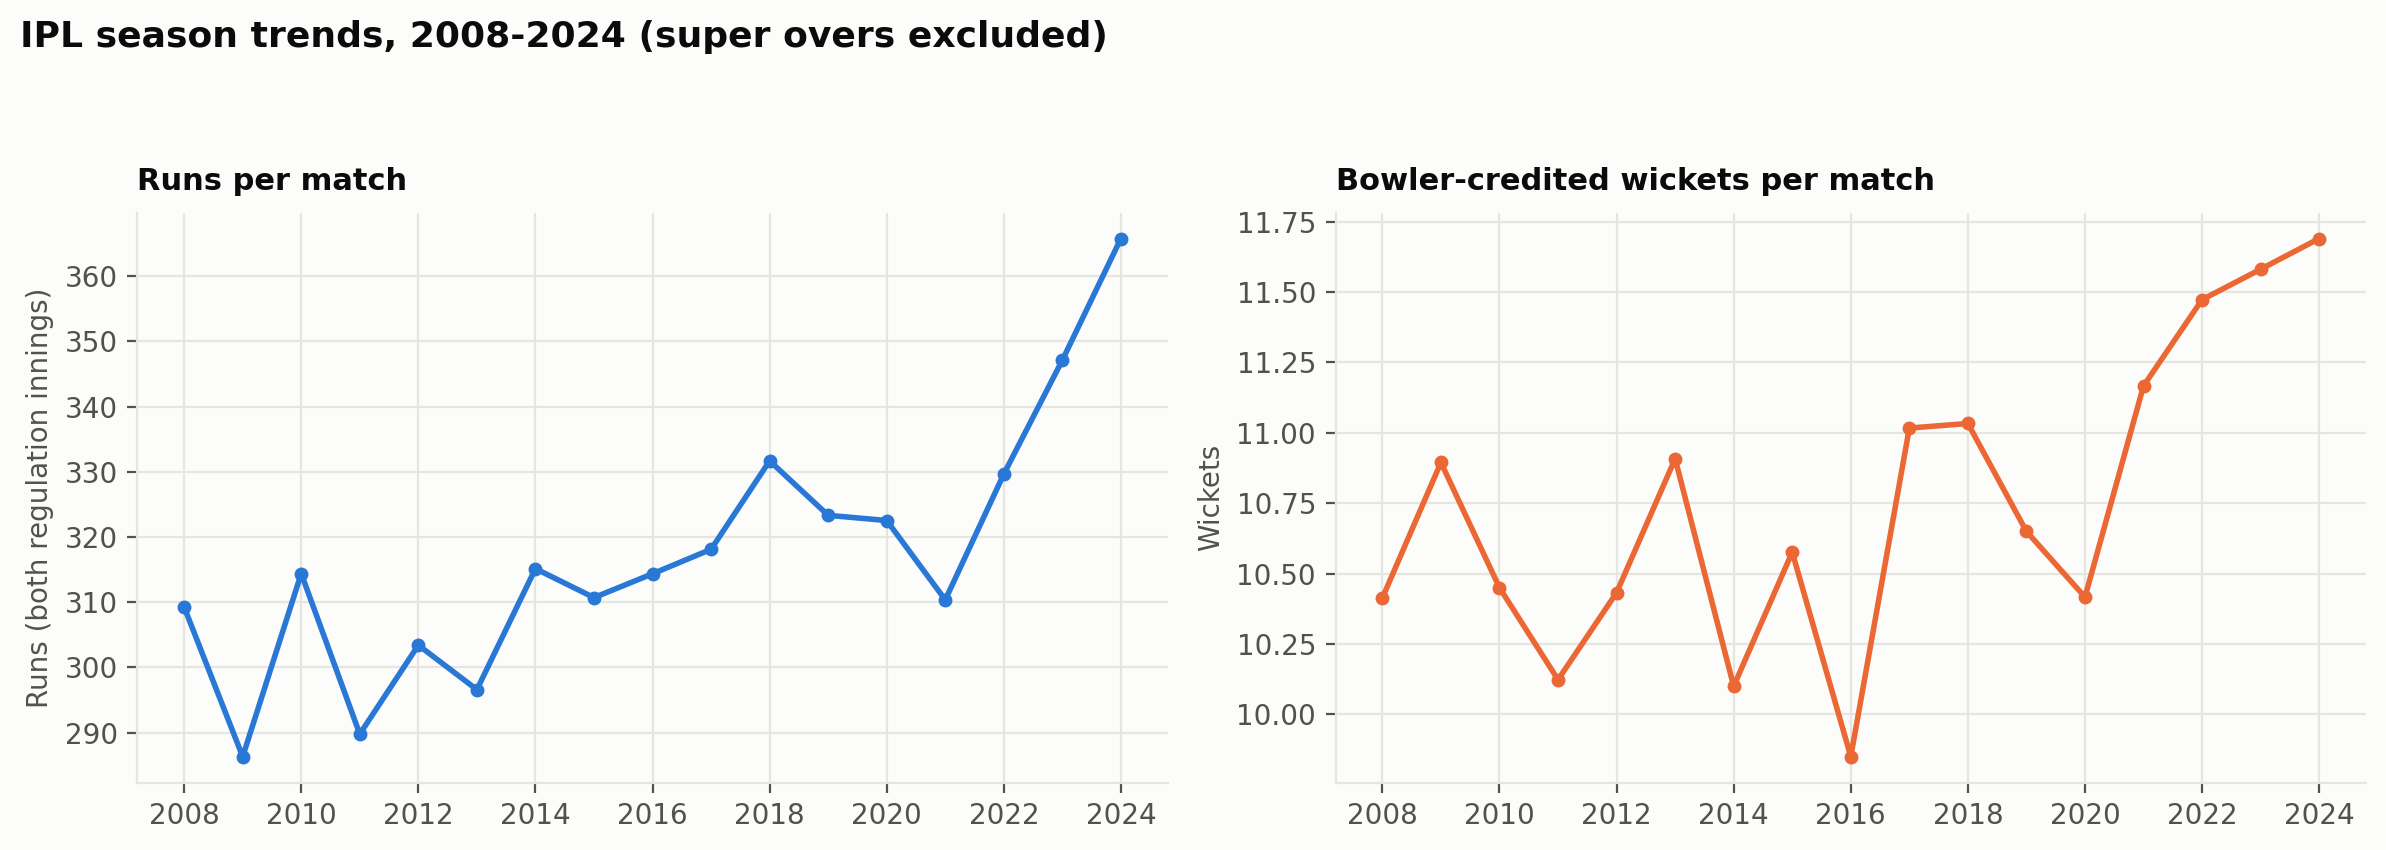

**Finding.** Total regulation runs grew from 17,937 in 2008 (58 matches) to 25,971 in 2024 (71 matches). Per match, scoring was broadly flat at ~286-332 runs between 2008 and 2022, then jumped to 347 (2023) and 366 (2024), the highest of any season (2024). Bowler-credited wickets per match stayed in a narrow band (9.8-11.7), so the recent increase comes from faster scoring, not fewer wickets. Sixes per match rose from 10.7 (2008) to 17.8 (2024).

**Limitation.** Season match counts reflect matches with play only (abandoned-without-a-ball games are absent).

In [3]:
show('A1')

### A2 · Average first-innings score by season

**Question.** Which seasons had the highest and lowest average first-innings scores?

**Why it matters.** First-innings score is the standard benchmark for 'par' at a venue or in a season.

**Metric.** Mean of inn1_runs over full matches (is_no_result = 0 and target_overs = 20).

,season_year,full_matches,avg_inn1
16,2024,70,190.1
15,2023,71,183.0
10,2018,57,172.1
14,2022,74,171.1
12,2020,60,169.5
11,2019,59,168.5
7,2015,53,167.8
9,2017,58,166.4
2,2010,60,164.8
8,2016,56,164.3


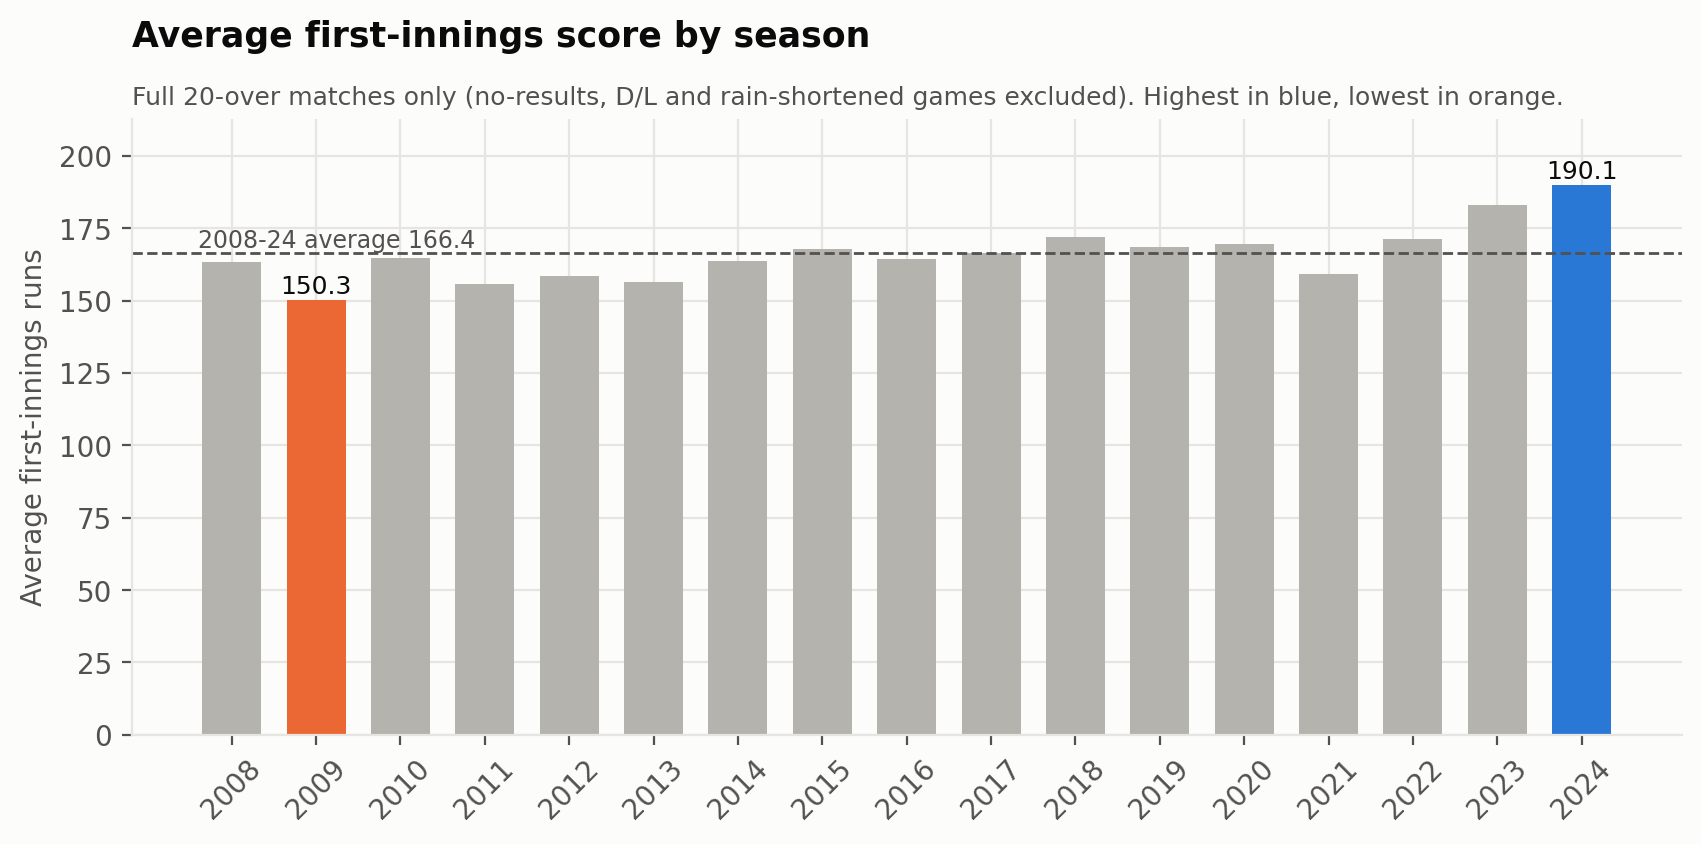

**Finding.** The highest average first-innings score was 190.1 in 2024; the lowest was 150.3 in 2009. Across all 1061 full matches the average is 166.4. From 2008 to 2022 every season averaged between 150.3 and 172.1; the average then rose sharply to 183.0 in 2023 (+11.9 on 2022) and 190.1 in 2024 (+7.1). The data does not record why; rule changes such as the Impact Player rule (introduced 2023) are a plausible but untested explanation.

**Limitation.** 34 matches excluded: 5 no-results and 29 D/L or rain-shortened matches.

In [4]:
show('A2')

### A3 · Runs per match and per innings

**Question.** How have average runs per match and runs per innings changed?

**Why it matters.** Separates the effect of more matches from genuinely higher scoring.

**Metric.** Runs per full match = mean(inn1_runs + inn2_runs) over full matches; runs per innings = that / 2.

,season_year,full_matches,runs_per_full_match,runs_per_innings_full,avg_inn1,avg_inn2
0,2008,54,315.2,157.6,163.3,151.9
1,2009,54,288.2,144.1,150.3,137.9
2,2010,60,314.4,157.2,164.8,149.6
3,2011,69,296.6,148.3,155.6,141.0
4,2012,73,304.9,152.4,158.4,146.5
5,2013,75,298.0,149.0,156.6,141.5
6,2014,58,318.3,159.1,163.7,154.6
7,2015,53,321.4,160.7,167.8,153.5
8,2016,56,320.6,160.3,164.3,156.2
9,2017,58,320.6,160.3,166.4,154.1


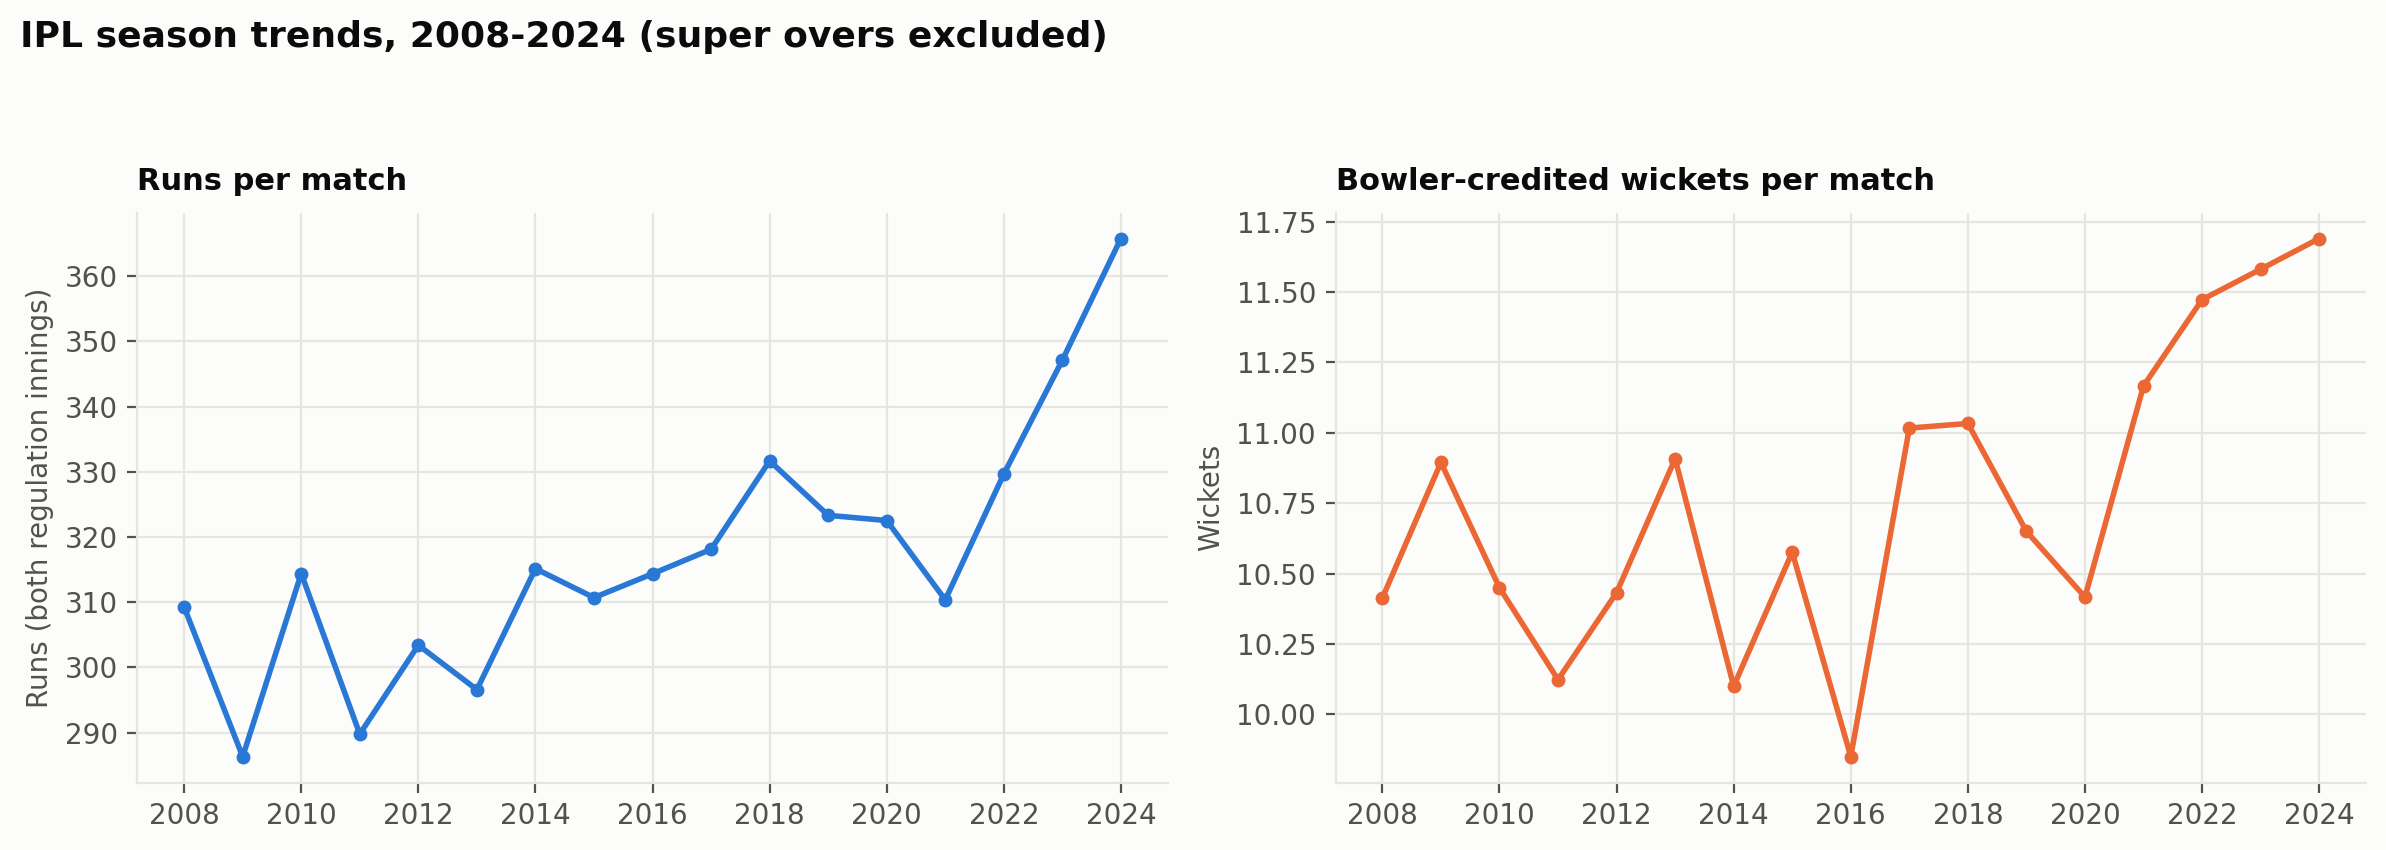

**Finding.** In full matches, runs per innings averaged 151.9 across 2008-2012 and 167.9 across 2020-2024. Second innings average fewer runs than first innings in every season (overall 153.8 vs 166.4), as expected because successful chases stop once the target is reached - so second-innings averages understate batting strength and should not be compared with first-innings averages as if like-for-like.

**Limitation.** Second-innings totals are truncated by the target (structural, not a data error).

In [5]:
show('A3')

### A4 · Scoring rate by season

**Question.** Which seasons had the highest scoring rates?

**Why it matters.** Run rate normalises for innings length and match count, making seasons directly comparable.

**Metric.** Run rate = sum(total_runs) / sum(is_legal_delivery) x 6 over regulation deliveries.

,season_year,run_rate,dot_pct,sixes_per_match,rr_Powerplay,rr_Middle,rr_Death
16,2024,9.56,32.92,17.76,9.46,8.83,11.21
15,2023,8.99,33.93,15.19,8.72,8.43,10.48
10,2018,8.65,34.42,14.53,8.42,8.06,10.14
14,2022,8.54,37.07,14.35,7.82,8.08,10.45
11,2019,8.41,35.64,13.07,8.13,7.73,10.16
9,2017,8.41,33.96,11.95,8.33,7.88,9.64
7,2015,8.37,36.31,11.73,7.76,7.84,10.31
0,2008,8.31,37.96,10.74,7.70,7.99,9.95
8,2016,8.31,34.14,10.65,7.70,7.86,10.17
12,2020,8.29,34.74,12.25,7.71,7.71,10.19


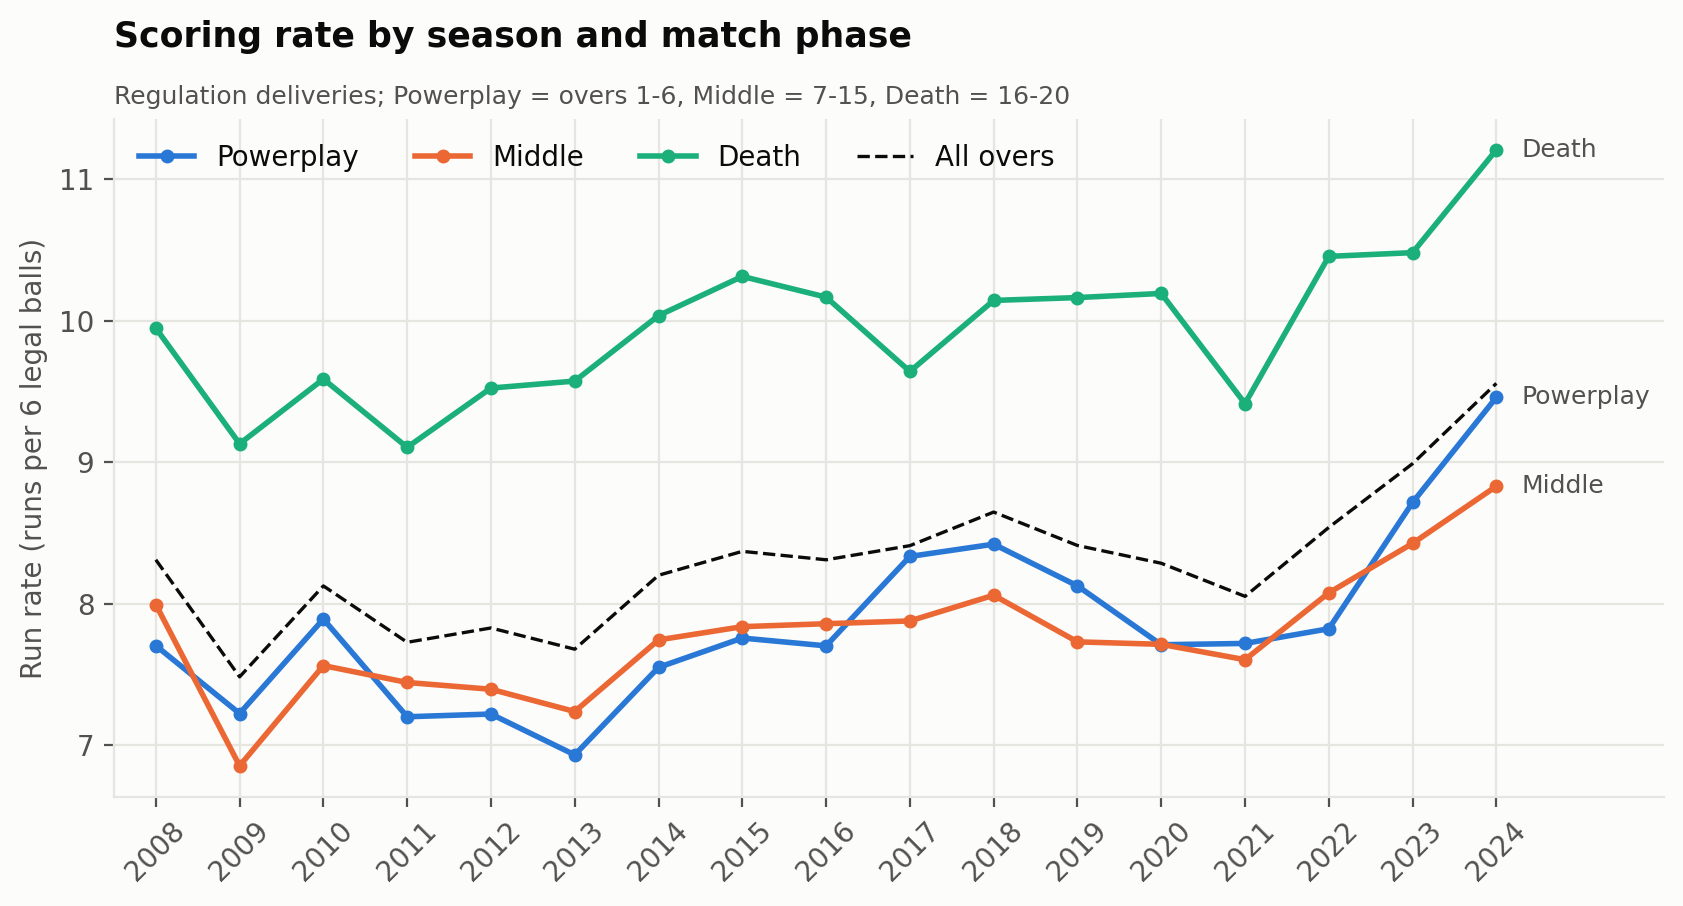

**Finding.** 2024 had the highest overall run rate (9.56 per over), followed by 2023 (8.99); the lowest was 2009 (7.48). Death overs are the fastest-scoring phase in 17 of 17 seasons. Between 2022 and 2024 the run rate rose in all three phases: Powerplay 7.82 -> 9.46, Middle 8.08 -> 8.83, Death 10.45 -> 11.21. The largest rise was in the Powerplay, so the increase was not confined to the end of the innings.

**Limitation.** Phase boundaries assume a 20-over innings (limitation L10).

In [6]:
show('A4')

### A5 · Participating franchises per season

In [7]:
show('A5')

**Question.** How has the number of participating franchises changed over time?

**Why it matters.** Unequal participation makes raw totals (wins, runs) unfair across franchises.

**Metric.** Distinct standardized franchises appearing in a season's matches.

,season_year,franchises,teams
0,2008,8,"Chennai Super Kings, Deccan Chargers, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rajasthan..."
1,2009,8,"Chennai Super Kings, Deccan Chargers, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rajasthan..."
2,2010,8,"Chennai Super Kings, Deccan Chargers, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rajasthan..."
3,2011,10,"Chennai Super Kings, Deccan Chargers, Delhi Capitals, Kochi Tuskers Kerala, Kolkata Knight Riders, Mumbai Indians, P..."
4,2012,9,"Chennai Super Kings, Deccan Chargers, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Pune Warriors, Punjab K..."
5,2013,9,"Chennai Super Kings, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Pune Warriors, Punjab Kings, Rajasthan R..."
6,2014,8,"Chennai Super Kings, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rajasthan Royals, Royal Ch..."
7,2015,8,"Chennai Super Kings, Delhi Capitals, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rajasthan Royals, Royal Ch..."
8,2016,8,"Delhi Capitals, Gujarat Lions, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rising Pune Supergiants, Royal C..."
9,2017,8,"Delhi Capitals, Gujarat Lions, Kolkata Knight Riders, Mumbai Indians, Punjab Kings, Rising Pune Supergiants, Royal C..."


**Finding.** The league ran with 8 franchises in most seasons, 10 in 2011 (Kochi Tuskers Kerala and Pune Warriors added), 9 in 2012-2013, back to 8 from 2014, and 10 since 2022 (Gujarat Titans and Lucknow Super Giants). Deccan Chargers (2008-12), Kochi (2011), Pune Warriors (2011-13), Gujarat Lions and Rising Pune Supergiants (2016-17) are defunct; Chennai Super Kings and Rajasthan Royals are absent in 2016-17. Franchise totals must therefore be read alongside seasons played.

## B. Team performance

### B1 · Most wins and titles

**Question.** Which franchises have the most wins?

**Why it matters.** Headline measure of franchise success across the league's history.

**Metric.** wins = matches where winner == team (super-over wins included). titles = Final matches won.

,team,seasons,matches,wins,losses,no_results,titles,playoff_matches
8,Mumbai Indians,17,261,144,117,0,5,20
0,Chennai Super Kings,15,238,138,99,1,5,26
6,Kolkata Knight Riders,17,251,131,120,0,3,15
13,Royal Challengers Bengaluru,17,255,123,129,3,0,16
2,Delhi Capitals,17,252,115,135,2,0,11
11,Rajasthan Royals,15,221,112,107,2,1,11
10,Punjab Kings,17,246,112,134,0,0,4
14,Sunrisers Hyderabad,12,182,88,94,0,1,14
1,Deccan Chargers,5,75,29,46,0,1,4
4,Gujarat Titans,3,45,28,17,0,1,5


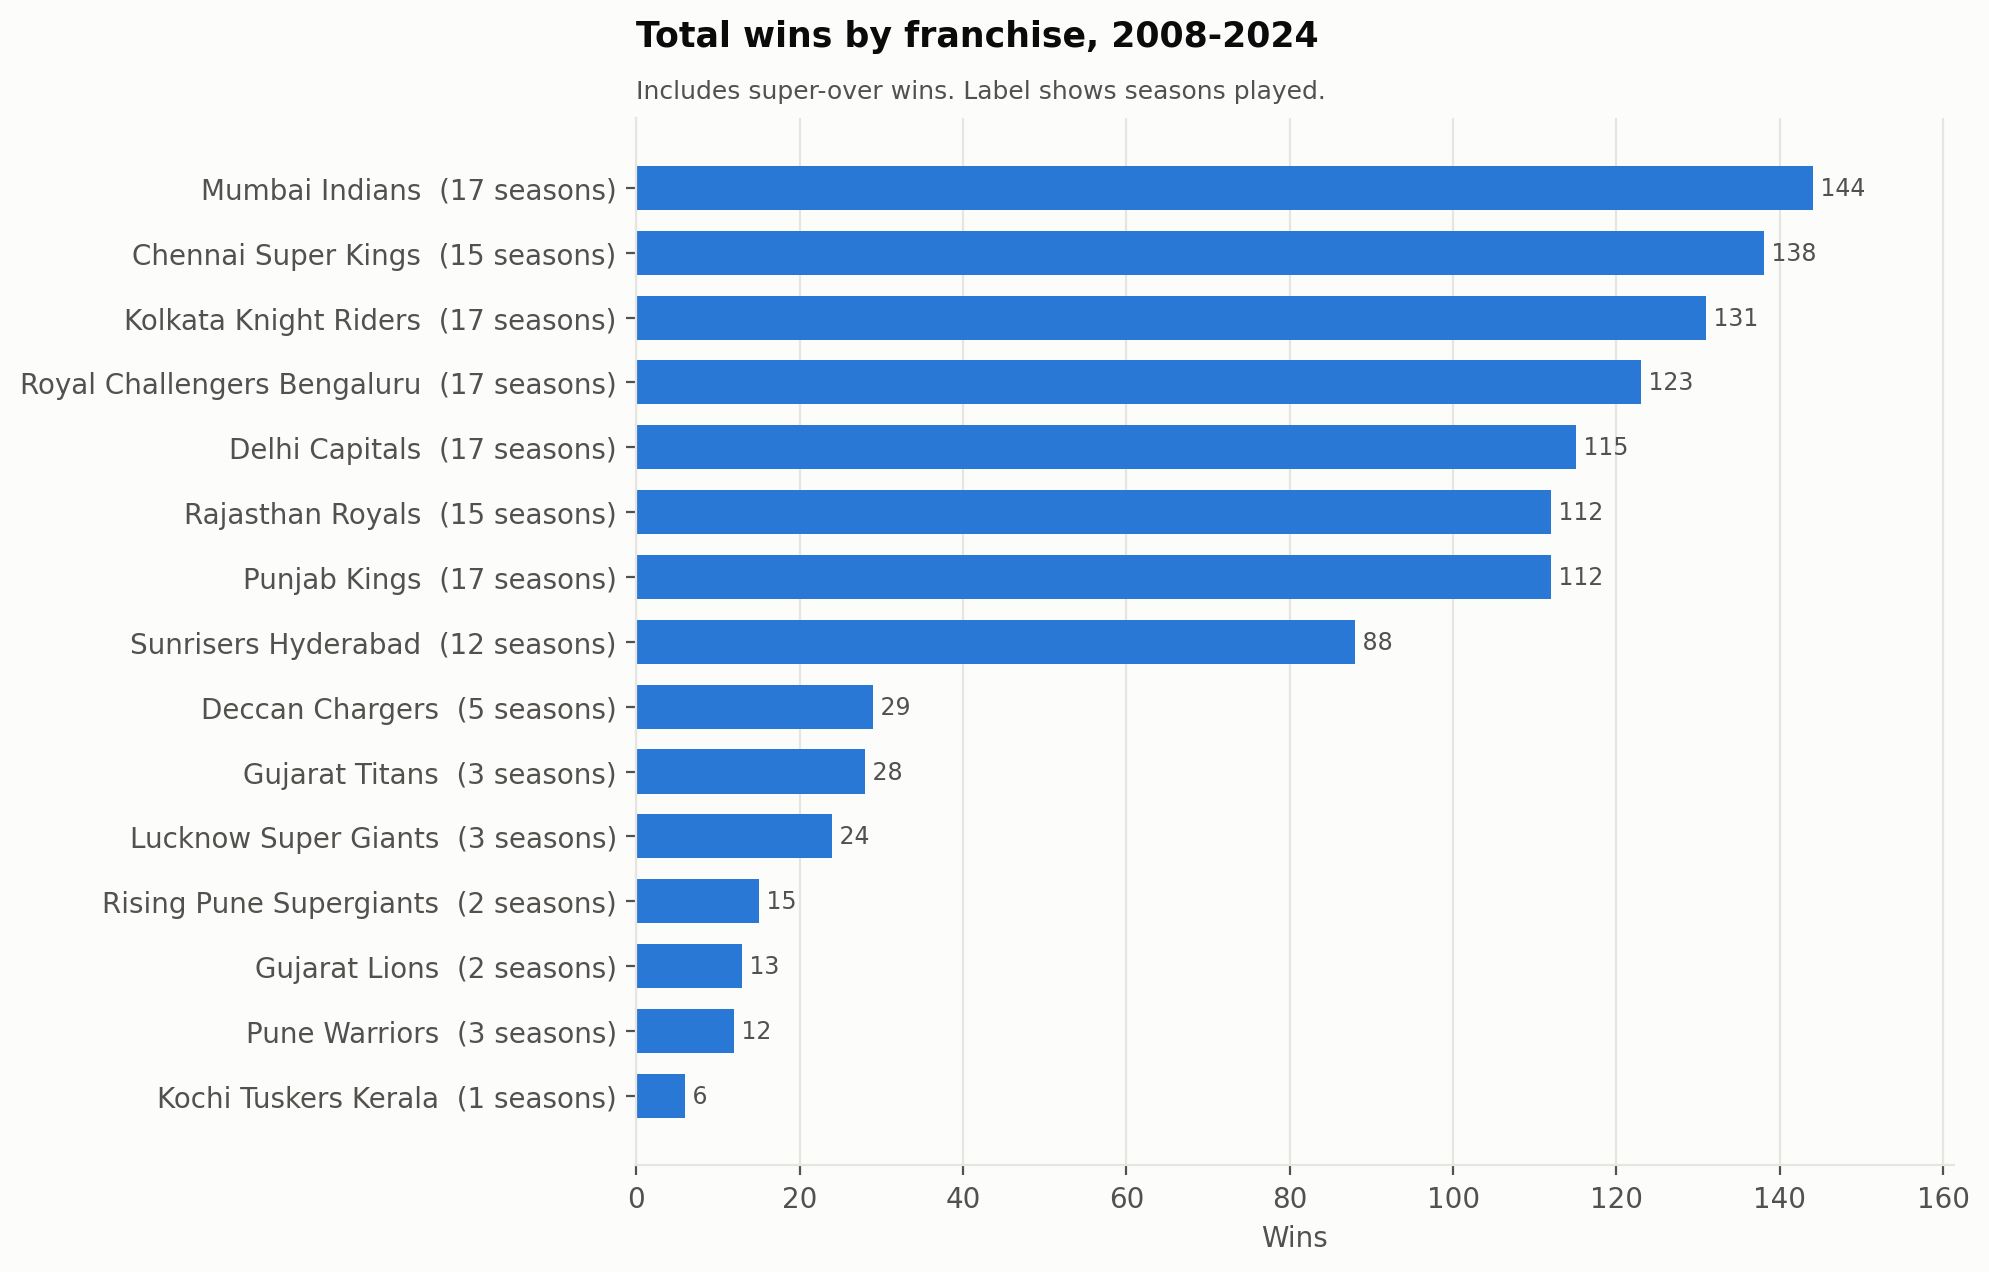

**Finding.** Mumbai Indians have the most wins (144) from 261 matches, followed by Chennai Super Kings (138) and Kolkata Knight Riders (131). Titles (Final winners) are concentrated: Mumbai Indians 5 and Chennai Super Kings 5, then Kolkata Knight Riders 3; together they hold 13 of 17 titles. Total wins favour long-serving franchises, so they are paired with win % (B2).

**Limitation.** Raw totals depend on seasons played (2 to 17).

In [8]:
show('B1')

### B2 · Win percentage

**Question.** Which franchises have the highest win percentage?

**Why it matters.** Win % normalises for different numbers of matches played.

**Metric.** win_pct = wins / decided matches x 100 (no-results excluded; ties settled by super over count as win/loss).

,team,seasons,decided,wins,losses,win_pct
4,Gujarat Titans,3,45,28,17,62.2
0,Chennai Super Kings,15,237,138,99,58.2
7,Lucknow Super Giants,3,43,24,19,55.8
8,Mumbai Indians,17,261,144,117,55.2
6,Kolkata Knight Riders,17,251,131,120,52.2
11,Rajasthan Royals,15,219,112,107,51.1
12,Rising Pune Supergiants,2,30,15,15,50.0
13,Royal Challengers Bengaluru,17,252,123,129,48.8
14,Sunrisers Hyderabad,12,182,88,94,48.4
2,Delhi Capitals,17,250,115,135,46.0


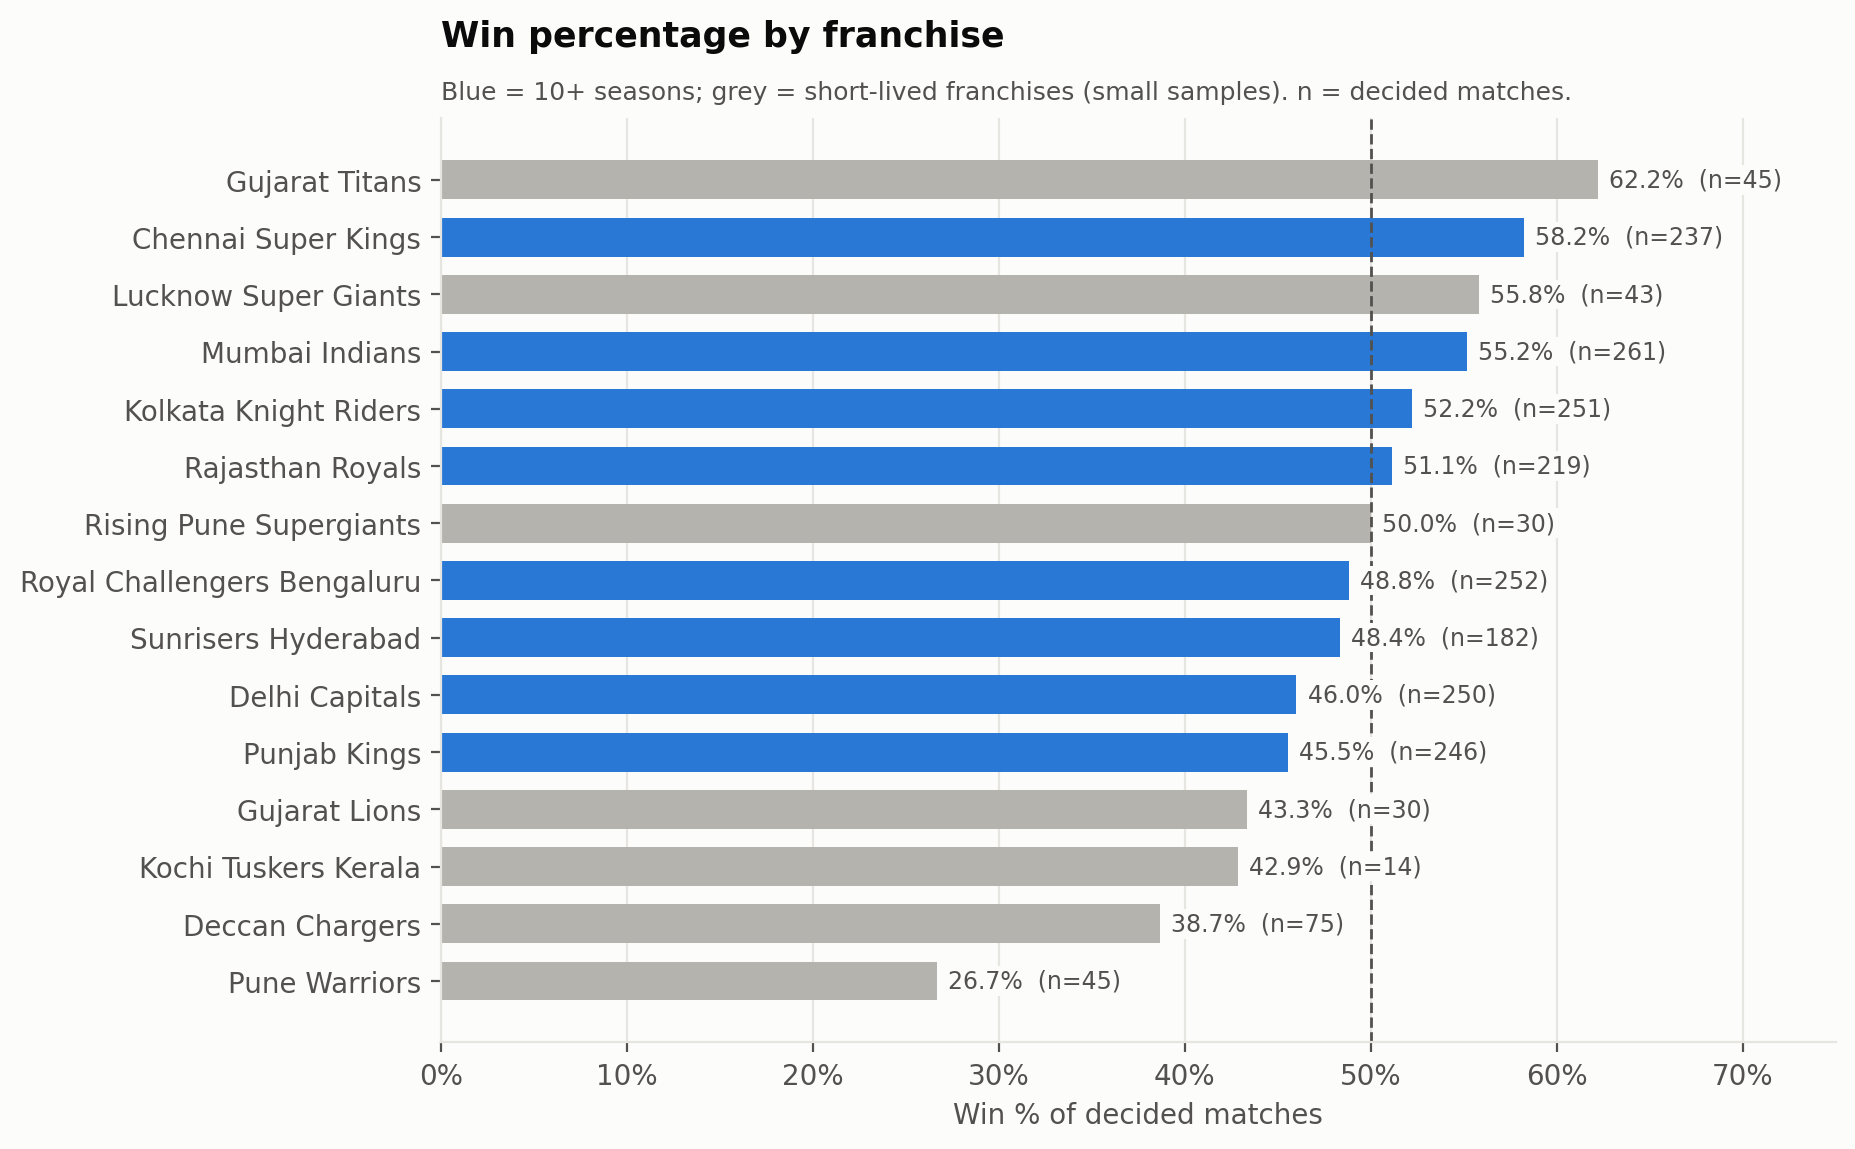

**Finding.** Among franchises with 10+ seasons, Chennai Super Kings have the highest win % (58.2%, 237 decided matches), then Mumbai Indians (55.2%). The overall leader is Gujarat Titans (62.2%) but from only 45 matches in 3 seasons, so its rate is far less certain. The lowest established franchise is Punjab Kings (45.5%).

**Limitation.** Franchises with <5 seasons have wide uncertainty; interpret with n.

In [9]:
show('B2')

### B3 · Batting-first performance

**Question.** Which franchises perform best when batting first?

**Why it matters.** Indicates which sides set and defend totals most effectively.

**Metric.** Matches where team == batting_first_team and result_for in {batting first, chasing}; win % = wins / those matches.

,team,bat_first_matches,bat_first_wins,bat_first_win_pct
7,Lucknow Super Giants,22,16,72.7
0,Chennai Super Kings,130,70,53.8
8,Mumbai Indians,132,71,53.8
4,Gujarat Titans,21,11,52.4
14,Sunrisers Hyderabad,94,44,46.8
13,Royal Challengers Bengaluru,126,57,45.2
6,Kolkata Knight Riders,118,52,44.1
11,Rajasthan Royals,100,43,43.0
2,Delhi Capitals,108,46,42.6
1,Deccan Chargers,43,18,41.9


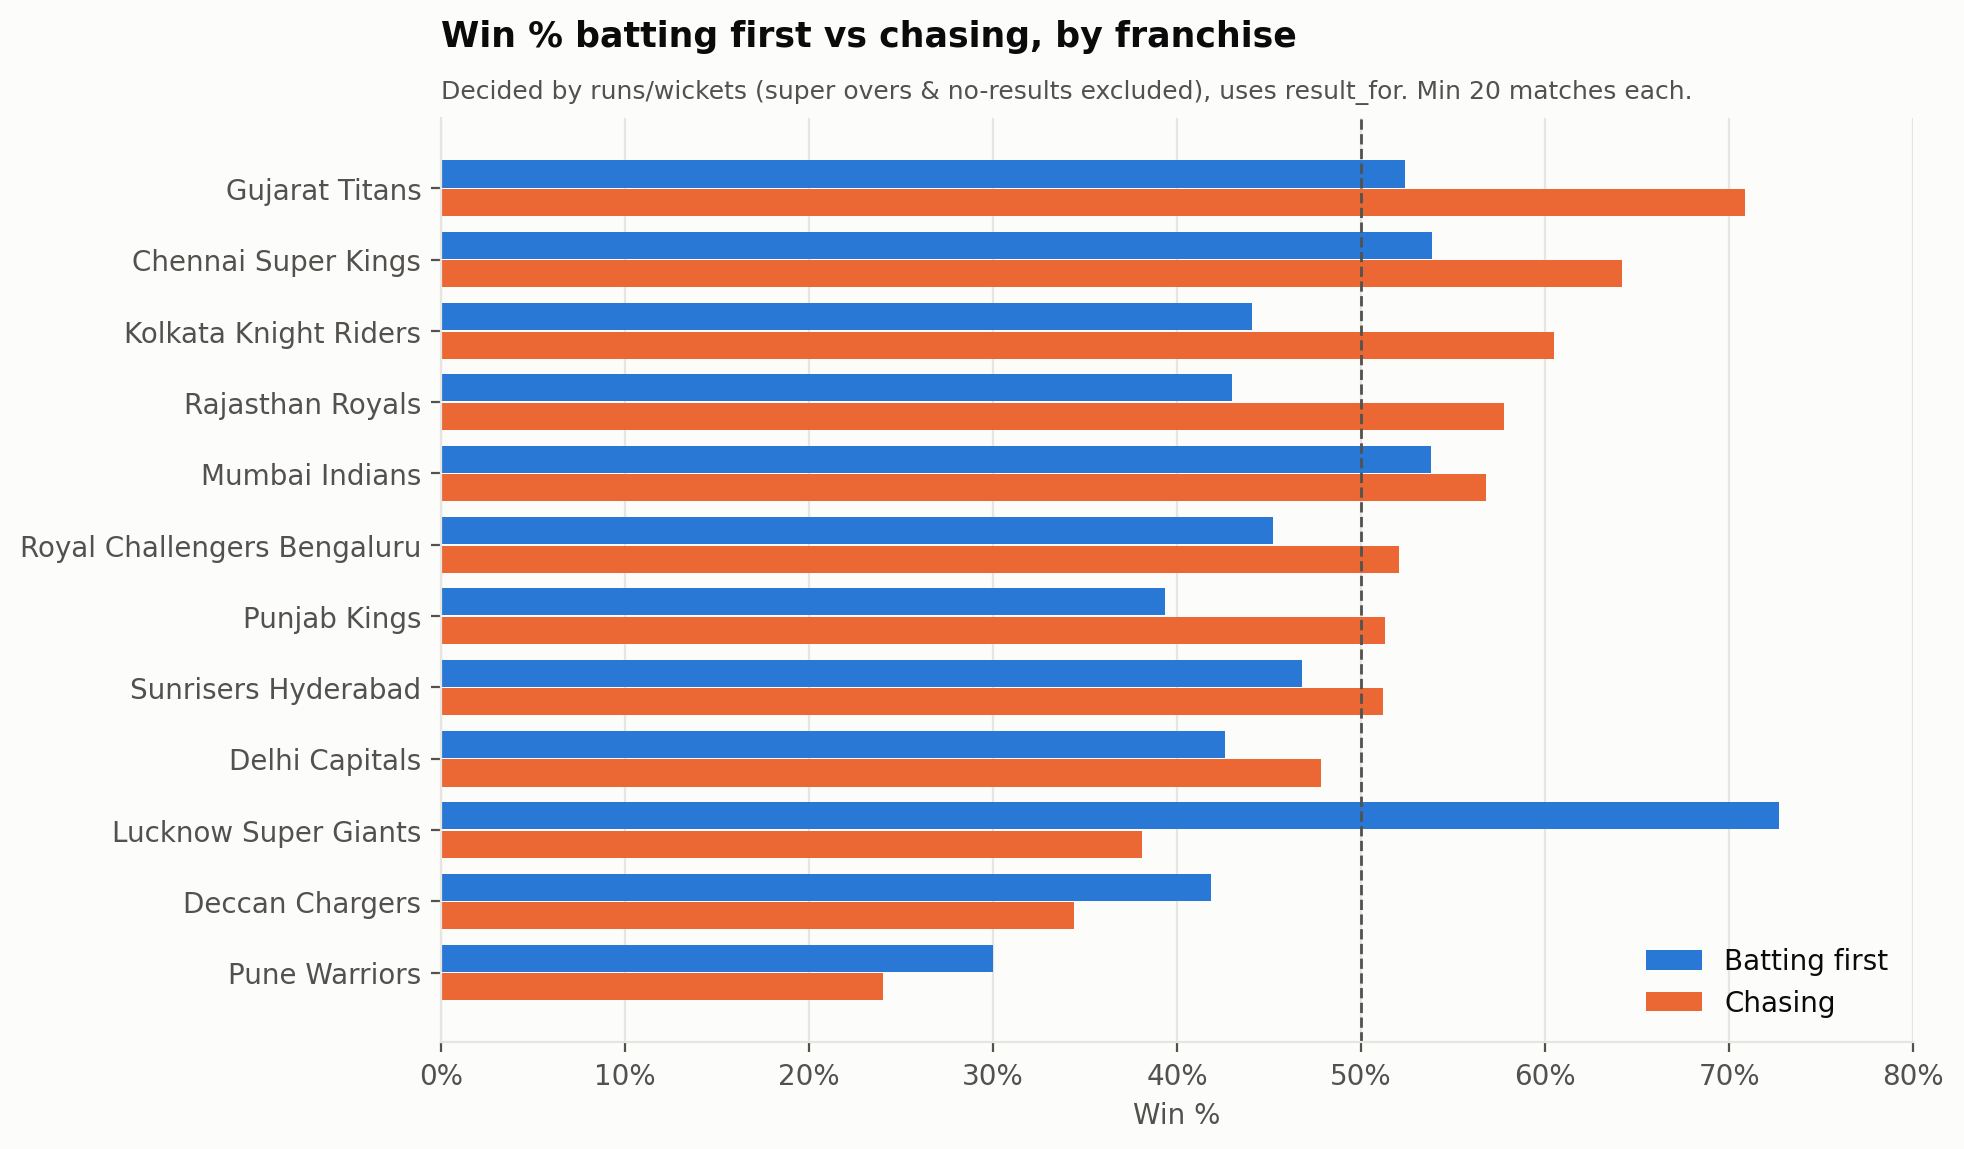

**Finding.** Batting first, Lucknow Super Giants have the best record (72.7% from 22 matches), followed by Chennai Super Kings (53.8%) and Mumbai Indians (53.8%). League-wide, batting-first sides won 45.7% of decided matches.

**Limitation.** Teams with < 20 batting-first matches excluded (Gujarat Lions, Kochi Tuskers Kerala, Rising Pune Supergiants).

In [10]:
show('B3')

### B4 · Chasing performance

**Question.** Which franchises perform best when chasing?

**Why it matters.** Chasing success shows composure under a known target.

**Metric.** Matches where team == chasing_team and result_for in {batting first, chasing}; win % = wins / matches. D/L chases won 'by runs' count as chasing wins (via result_for).

,team,chase_matches,chase_wins,chase_win_pct
4,Gujarat Titans,24,17,70.8
0,Chennai Super Kings,106,68,64.2
6,Kolkata Knight Riders,129,78,60.5
11,Rajasthan Royals,116,67,57.8
8,Mumbai Indians,125,71,56.8
13,Royal Challengers Bengaluru,123,64,52.0
10,Punjab Kings,115,59,51.3
14,Sunrisers Hyderabad,84,43,51.2
2,Delhi Capitals,138,66,47.8
7,Lucknow Super Giants,21,8,38.1


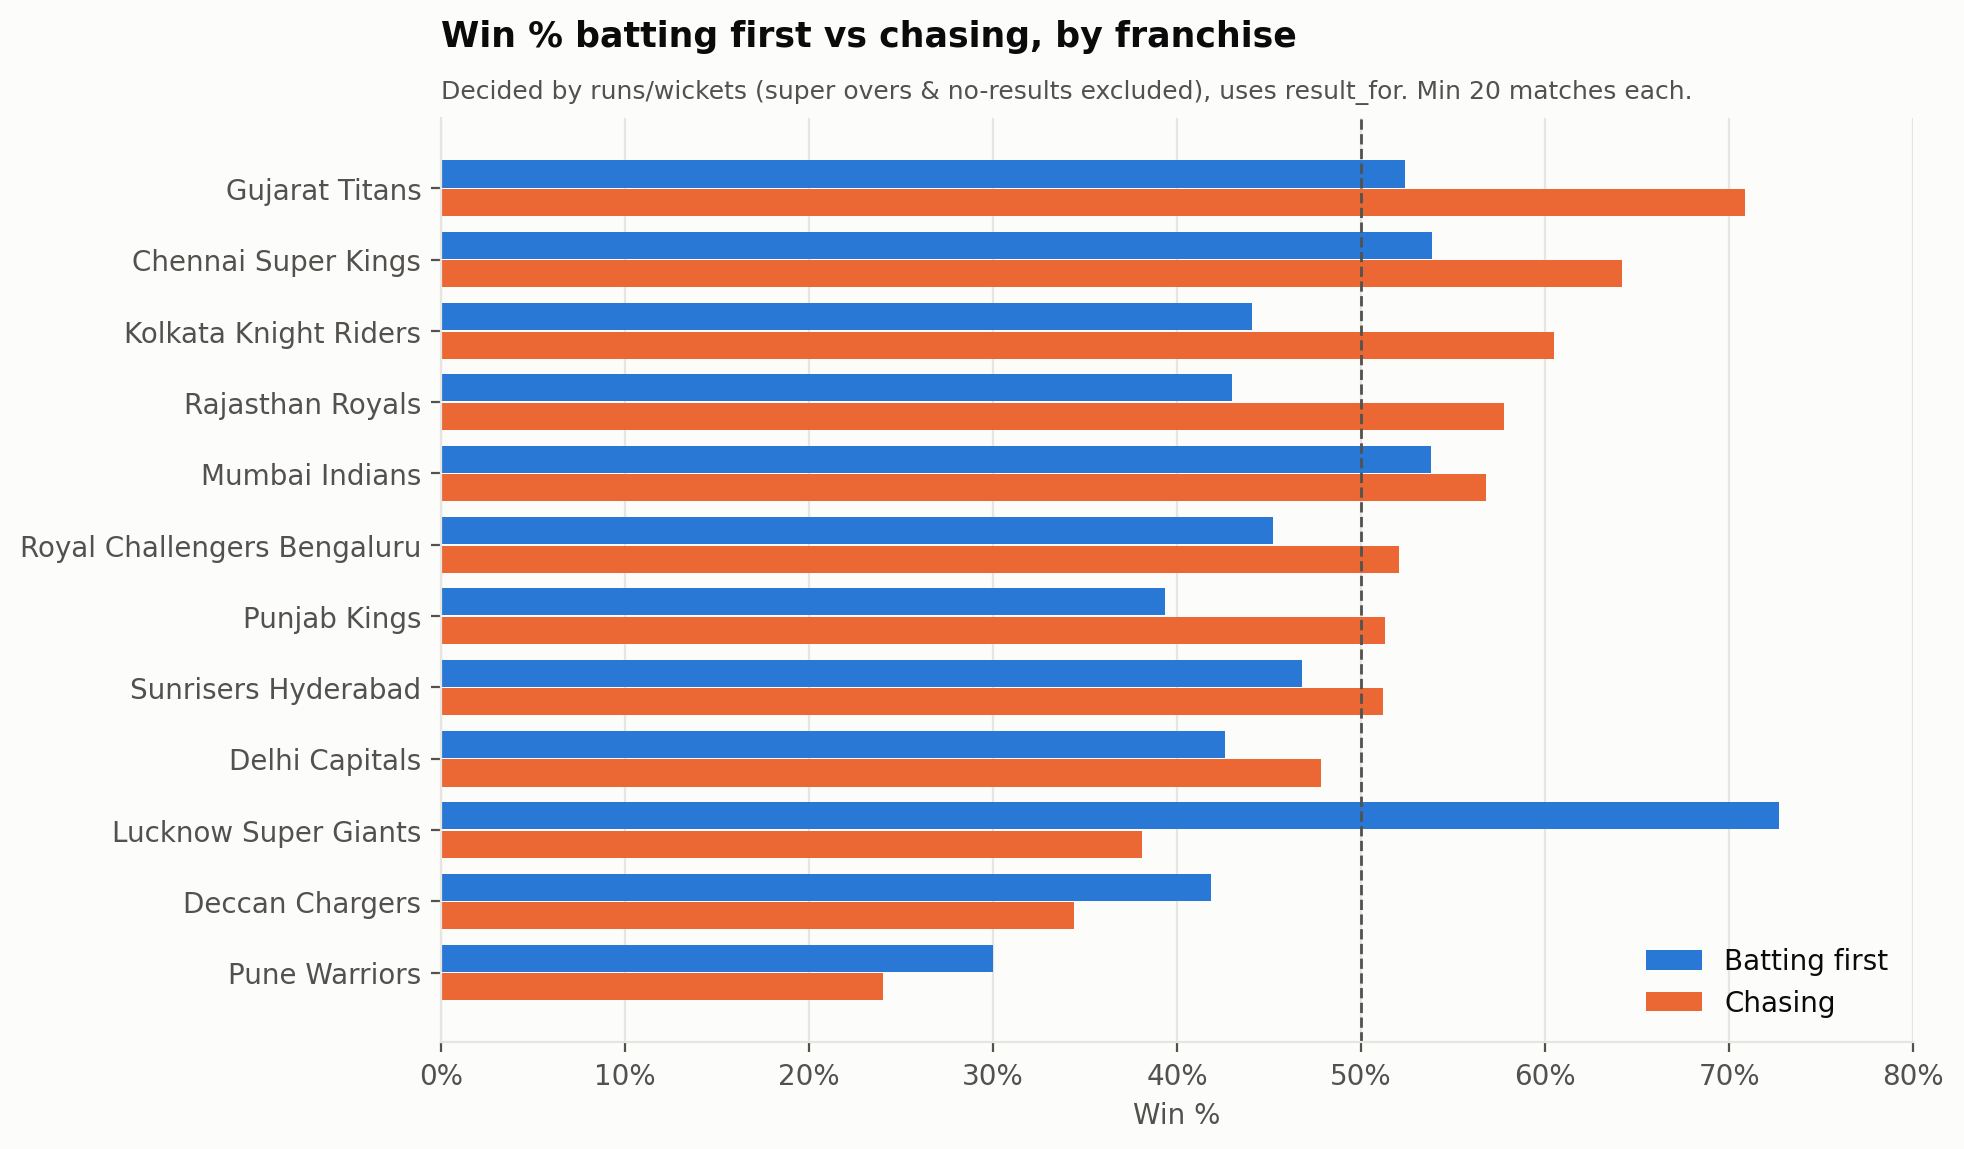

**Finding.** Chasing, Gujarat Titans lead (70.8% from 24), then Chennai Super Kings (64.2%). The biggest preference for chasing over batting first is Gujarat Titans (+18.5 points); the biggest preference for batting first is Lucknow Super Giants (-34.6 points). These are observed records - they also reflect toss decisions, opponents and eras, not only a team's skill in that role.

**Limitation.** Same thresholds as B3.

In [11]:
show('B4')

### B5 · Average first- and second-innings scores

In [12]:
show('B5')

**Question.** Which teams have the highest average first-innings and second-innings scores?

**Why it matters.** Measures batting strength while separating the setting and chasing roles.

**Metric.** Full matches only. avg_inn1 = mean inn1_runs as batting_first_team; avg_inn2 = mean inn2_runs as chasing_team; avg_inn1_vs_season = mean(inn1_runs - season mean inn1_runs).

,team,inn1_innings,avg_inn1,inn2_innings,avg_inn2,avg_inn1_vs_season
7,Lucknow Super Giants,22,181.4,21,161.7,0.1
4,Gujarat Titans,20,177.0,24,166.8,-3.9
0,Chennai Super Kings,126,170.7,104,156.0,5.1
13,Royal Challengers Bengaluru,125,169.9,119,152.4,2.9
14,Sunrisers Hyderabad,90,168.9,87,152.1,-0.8
8,Mumbai Indians,134,166.7,125,156.2,1.4
6,Kolkata Knight Riders,113,166.3,124,153.0,-0.2
10,Punjab Kings,124,164.5,114,158.6,-1.3
11,Rajasthan Royals,102,163.8,115,153.6,-2.3
2,Delhi Capitals,107,163.4,136,151.8,-3.0


**Finding.** On raw averages, Lucknow Super Giants post the highest first-innings score (181.4) - but they played only in 2022-24, the highest-scoring era. Adjusting for season (score minus that season's league average), the strongest first-innings batting sides are Chennai Super Kings (+5.1 runs vs season average) and Royal Challengers Bengaluru (+2.9); the weakest is Pune Warriors (-8.2). Highest average second-innings score: Gujarat Titans (166.8), which is truncated by the target and so not like-for-like.

**Limitation.** Raw averages are biased by era (teams active only in 2022-24 look stronger).

### B6 · Team bowling strength

**Question.** Which teams have the strongest bowling performance based on clearly defined measures?

**Why it matters.** Bowling quality is the other half of team strength; era adjustment makes 2008 and 2024 comparable.

**Metric.** economy = runs conceded (total_runs incl. extras) / legal balls x 6; economy_vs_league = (runs - expected) / balls x 6 where expected = balls x league runs-per-ball in that season; balls_per_dismissal = legal balls / player outs (incl. run outs, a team fielding outcome).

,team,balls,runs,outs,economy,economy_vs_league,balls_per_dismissal,dot_pct
12,Rising Pune Supergiants,3420,4549,189,7.98,-0.38,18.10,36.17
4,Gujarat Titans,5140,7475,297,8.73,-0.25,17.31,36.01
0,Chennai Super Kings,27529,37197,1479,8.11,-0.16,18.61,36.45
14,Sunrisers Hyderabad,21013,29068,1073,8.30,-0.15,19.58,35.94
7,Lucknow Super Giants,5009,7415,264,8.88,-0.13,18.97,35.46
6,Kolkata Knight Riders,28661,39045,1461,8.17,-0.10,19.62,36.22
8,Mumbai Indians,30245,41251,1585,8.18,-0.10,19.08,36.56
5,Kochi Tuskers Kerala,1555,1986,74,7.66,-0.06,21.01,40.26
9,Pune Warriors,5311,6857,238,7.75,0.00,22.32,36.32
11,Rajasthan Royals,25361,35101,1269,8.30,0.02,19.99,35.57


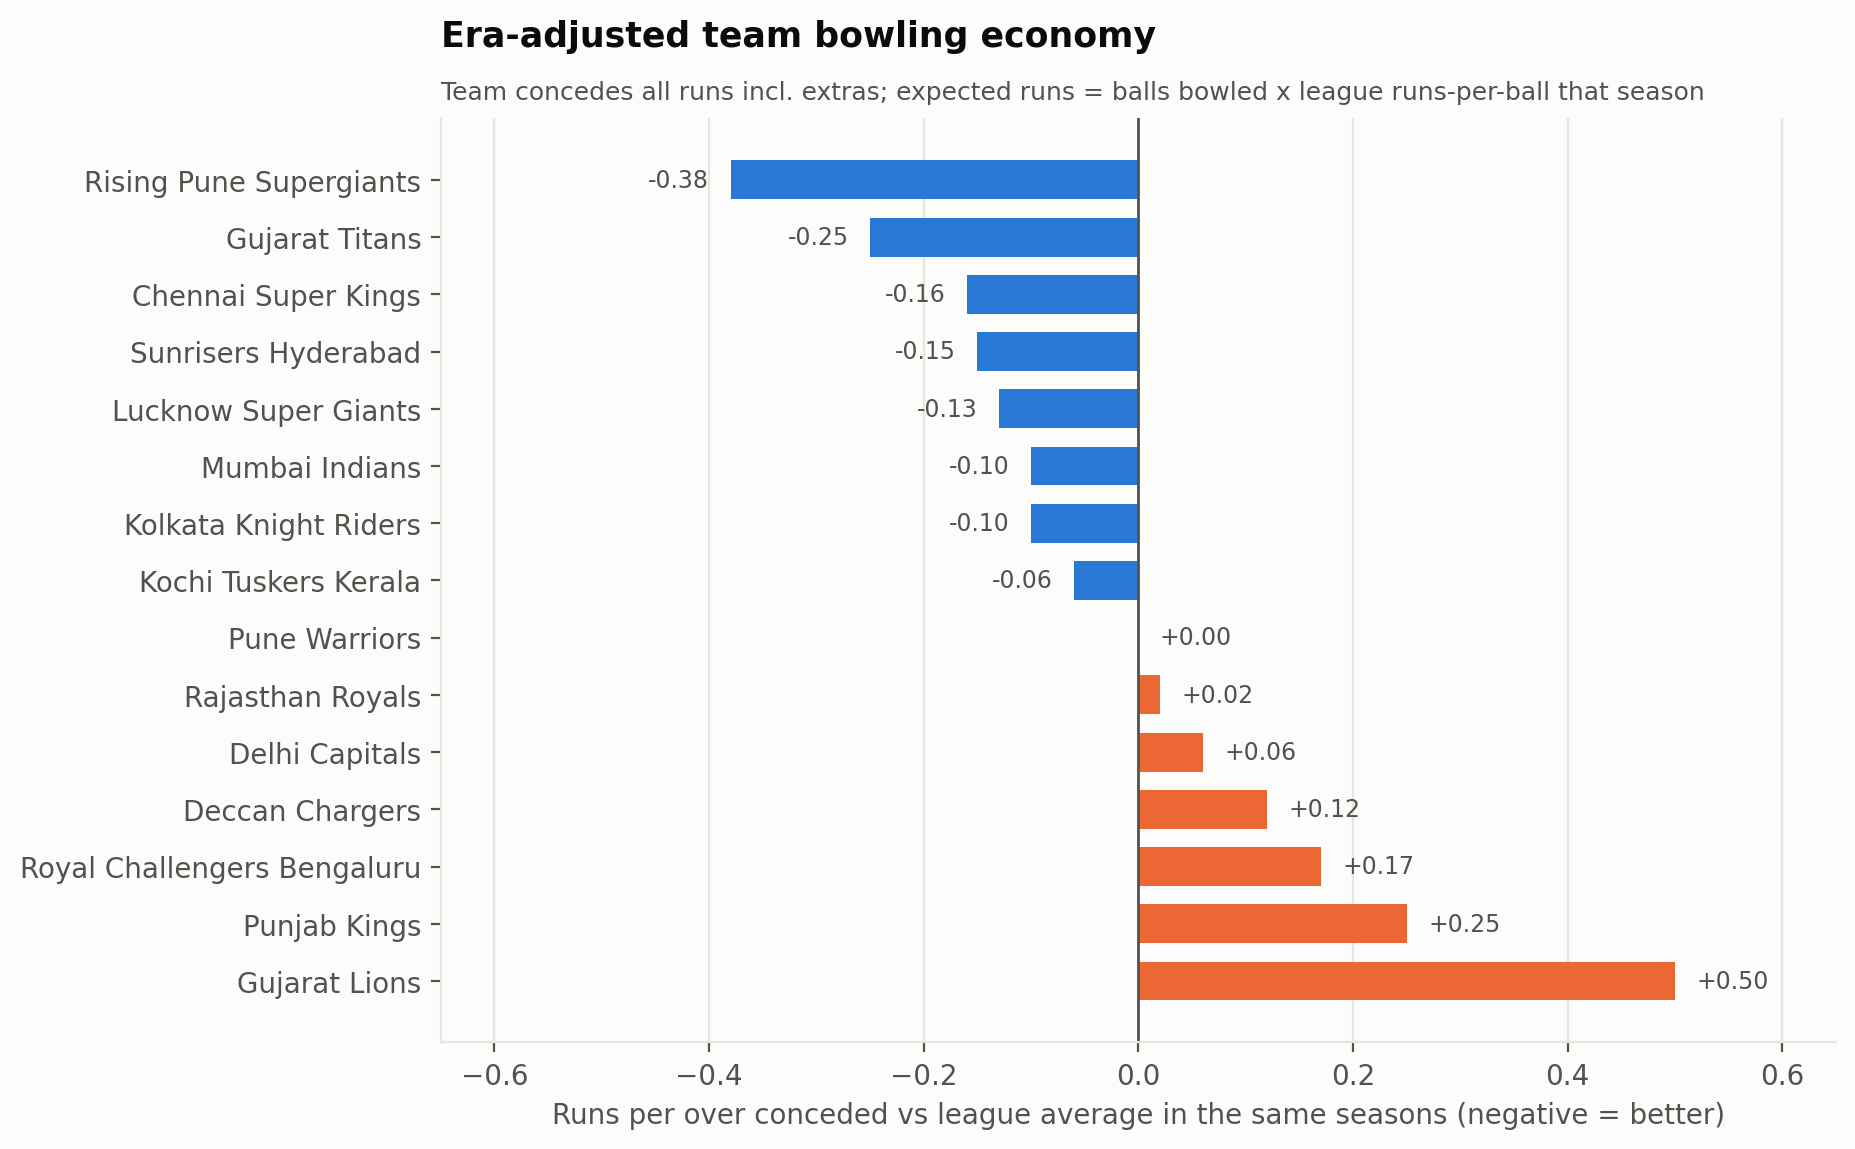

**Finding.** After adjusting for each season's scoring level, Rising Pune Supergiants (2 seasons) have conceded the fewest runs relative to the league (-0.38 runs/over), followed by Gujarat Titans (3 seasons, -0.25); both are small samples. Among franchises with 10+ seasons the best is Chennai Super Kings (-0.16) and the most expensive is Punjab Kings (+0.25); overall the most expensive is Gujarat Lions (+0.50). Raw economy alone would mislead: Gujarat Titans' raw economy (8.73) ranks 3 highest of 15 because they played only in 2022-24, yet relative to those seasons it is -0.25. Best wicket-taking frequency: Gujarat Titans (17.3 balls per dismissal).

**Limitation.** Does not adjust for venue or opposition strength.

In [13]:
show('B6')

## C. Batting analysis

### C1 · Leading run scorers

**Question.** Who are the leading run scorers?

**Why it matters.** Career run aggregates identify the league's most productive batters.

**Metric.** runs = sum(batsman_runs); innings = (match, innings) in which the player appeared as striker, non-striker or was dismissed; balls = sum(is_ball_faced).

,player,innings,runs,balls,outs,not_outs,average,strike_rate,highest,fifties,hundreds,fours,sixes
635,V Kohli,244,8004,6065,207,37,38.67,131.97,113,55,8,706,273
515,S Dhawan,221,6769,5324,192,29,35.26,127.14,106,51,2,768,153
480,RG Sharma,252,6628,5054,223,29,29.72,131.14,109,43,2,599,281
150,DA Warner,184,6565,4697,162,22,40.52,139.77,126,62,4,663,236
549,SK Raina,200,5528,4043,170,30,32.52,136.73,100,39,1,506,203
377,MS Dhoni,229,5243,3812,134,95,39.13,137.54,84,24,0,363,252
31,AB de Villiers,170,5162,3403,130,40,39.71,151.69,133,40,3,413,251
127,CH Gayle,141,4965,3333,125,16,39.72,148.96,175,31,6,405,357
504,RV Uthappa,197,4952,3799,180,17,27.51,130.35,88,27,0,481,182
285,KD Karthik,234,4842,3577,184,50,26.32,135.36,97,22,0,466,161


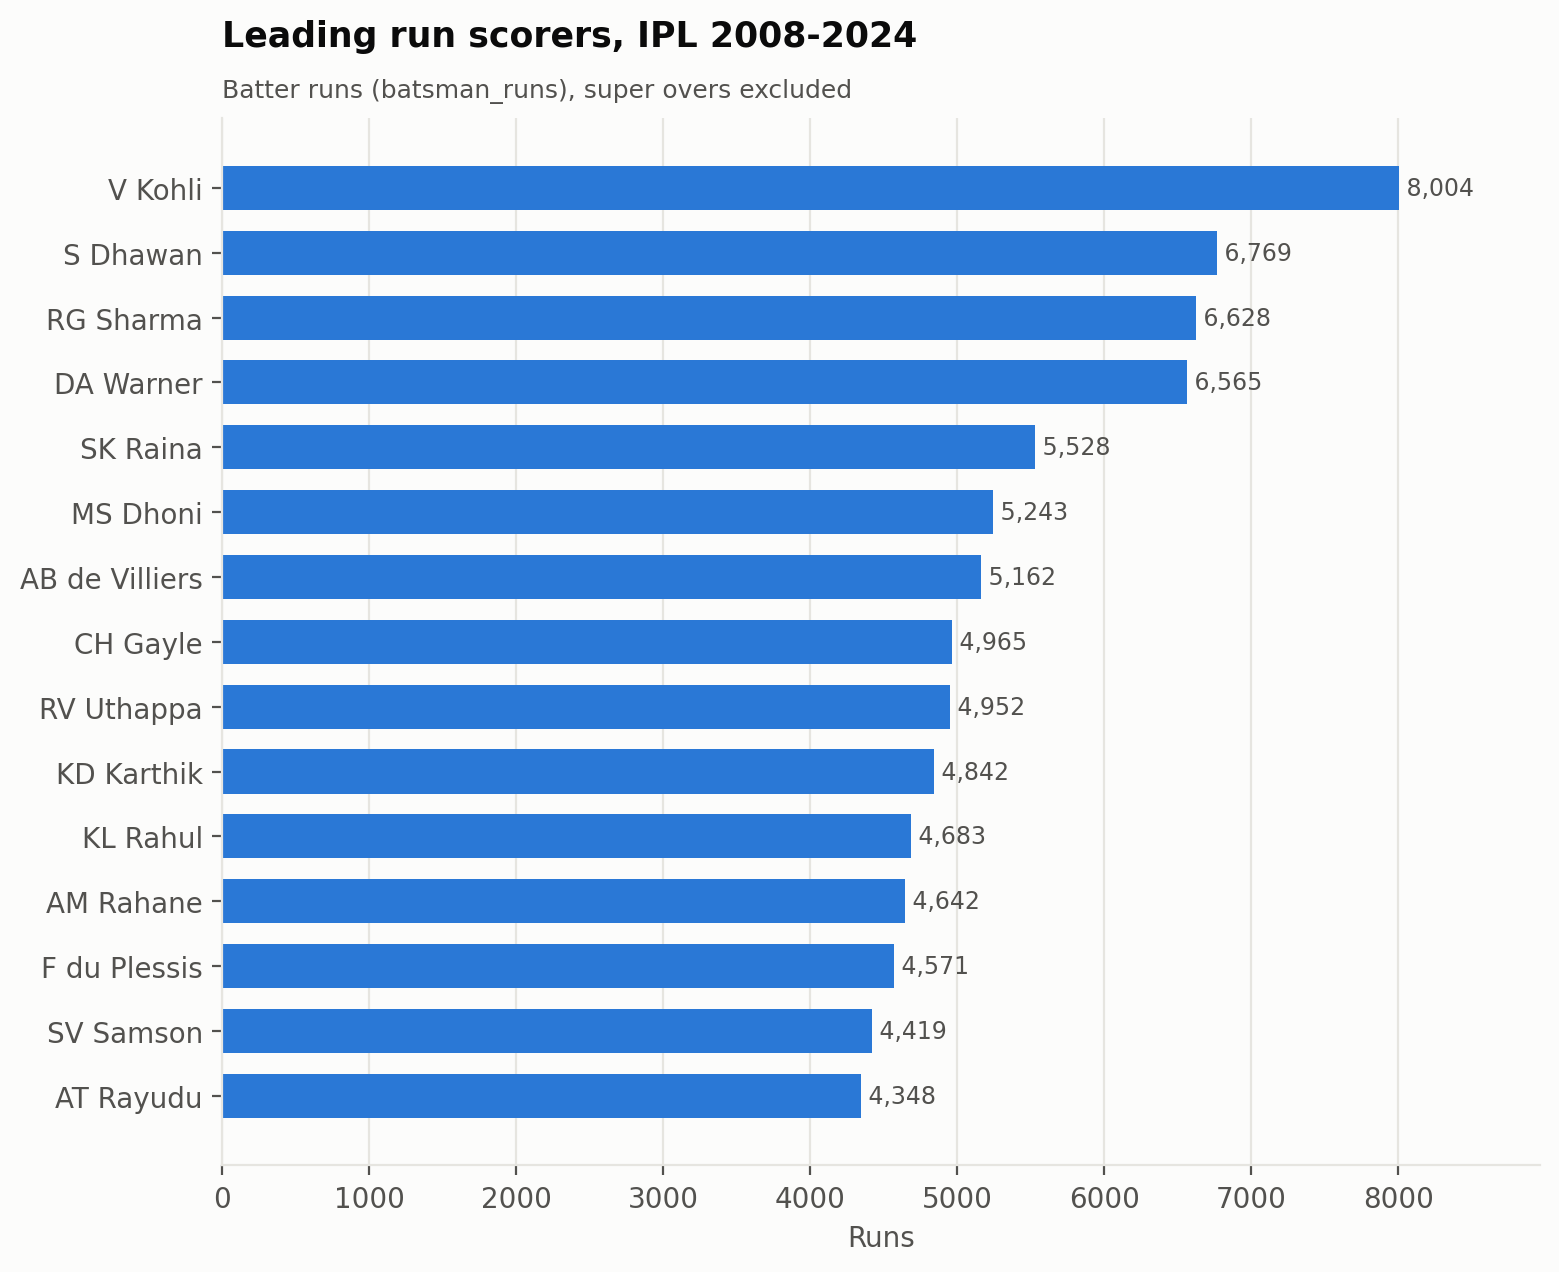

**Finding.** V Kohli leads with 8,004 runs in 244 innings (average 38.67, strike rate 131.97), 1,235 clear of S Dhawan (6,769). RG Sharma (6,628) and DA Warner (6,565) complete the top four. Kohli's total matches the published figure of 8,004 (see validation report).

**Limitation.** Volume measure - rewards longevity.

In [14]:
show('C1')

### C2 · Batting average

**Question.** Who has the highest batting average among players meeting a reasonable minimum-innings threshold?

**Why it matters.** Average measures runs per dismissal - how expensive a batter is to get out.

**Metric.** average = runs / outs (outs = is_player_out where player_dismissed = player; retired hurt not out). Minimum 50 innings.

,player,innings,runs,balls,outs,not_outs,average,strike_rate,highest,fifties,hundreds,fours,sixes
292,KL Rahul,123,4683,3479,103,20,45.47,134.61,132,37,4,400,187
476,RD Gaikwad,65,2380,1739,57,8,41.75,136.86,108,18,2,217,91
150,DA Warner,184,6565,4697,162,22,40.52,139.77,126,62,4,663,236
545,SE Marsh,69,2477,1866,62,7,39.95,132.74,115,20,1,266,78
264,JP Duminy,77,2029,1636,51,26,39.78,124.02,78,14,0,126,79
127,CH Gayle,141,4965,3333,125,16,39.72,148.96,175,31,6,405,357
31,AB de Villiers,170,5162,3403,130,40,39.71,151.69,133,40,3,413,251
377,MS Dhoni,229,5243,3812,134,95,39.13,137.54,84,24,0,363,252
355,MEK Hussey,58,1977,1612,51,7,38.76,122.64,116,15,1,198,52
635,V Kohli,244,8004,6065,207,37,38.67,131.97,113,55,8,706,273


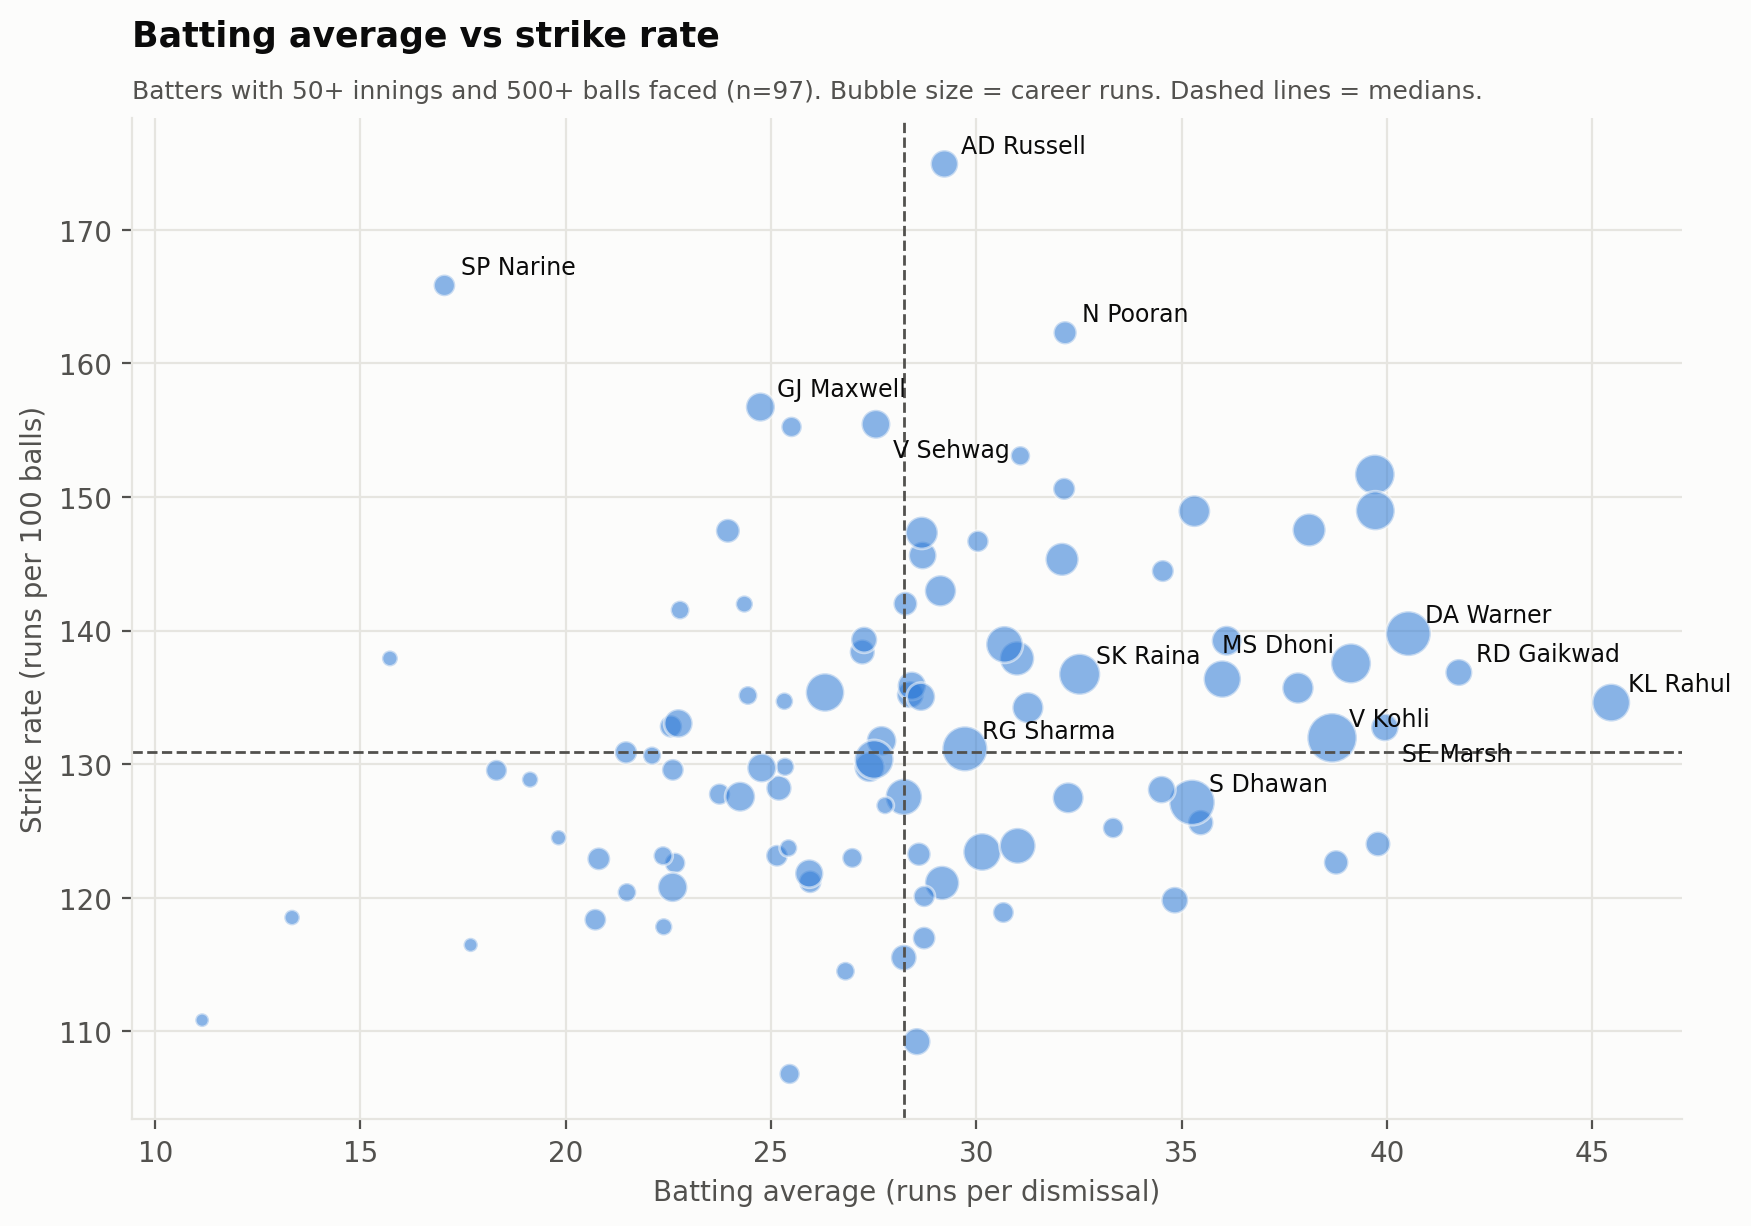

**Finding.** With at least 50 innings (103 qualifying batters), KL Rahul has the highest average (45.47, 123 innings), followed by RD Gaikwad (41.75) and DA Warner (40.52). Averages are inflated by not-outs (e.g. MS Dhoni has 95 not-outs in this list), which is why strike rate and consistency (C3, C4) are read alongside.

**Limitation.** Finishers who often bat late and remain not out have inflated averages.

In [15]:
show('C2')

### C3 · Strike rate

**Question.** Who has the highest strike rate among players meeting a reasonable minimum-balls threshold?

**Why it matters.** In T20, scoring speed matters as much as not getting out.

**Metric.** strike_rate = runs / balls faced x 100 (balls faced exclude wides). Minimum 500 balls.

,player,innings,runs,balls,outs,not_outs,average,strike_rate,highest,fifties,hundreds,fours,sixes
40,AD Russell,105,2484,1420,85,20,29.22,174.93,88,11,0,170,209
211,H Klaasen,32,993,590,26,6,38.19,168.31,104,6,1,56,64
564,SP Narine,110,1534,925,90,20,17.04,165.84,109,7,1,164,97
326,LS Livingstone,39,939,578,33,6,28.45,162.46,94,6,0,66,66
399,N Pooran,73,1769,1090,55,18,32.16,162.29,77,9,0,113,127
488,RM Patidar,24,799,503,23,1,34.74,158.85,112,7,1,51,54
206,GJ Maxwell,129,2771,1768,112,17,24.74,156.73,95,18,0,233,160
637,V Sehwag,104,2728,1755,99,5,27.56,155.44,122,16,2,334,106
71,Abhishek Sharma,61,1377,887,54,7,25.50,155.24,75,7,0,128,73
560,SO Hetmyer,66,1243,812,40,26,31.08,153.08,75,4,0,76,82


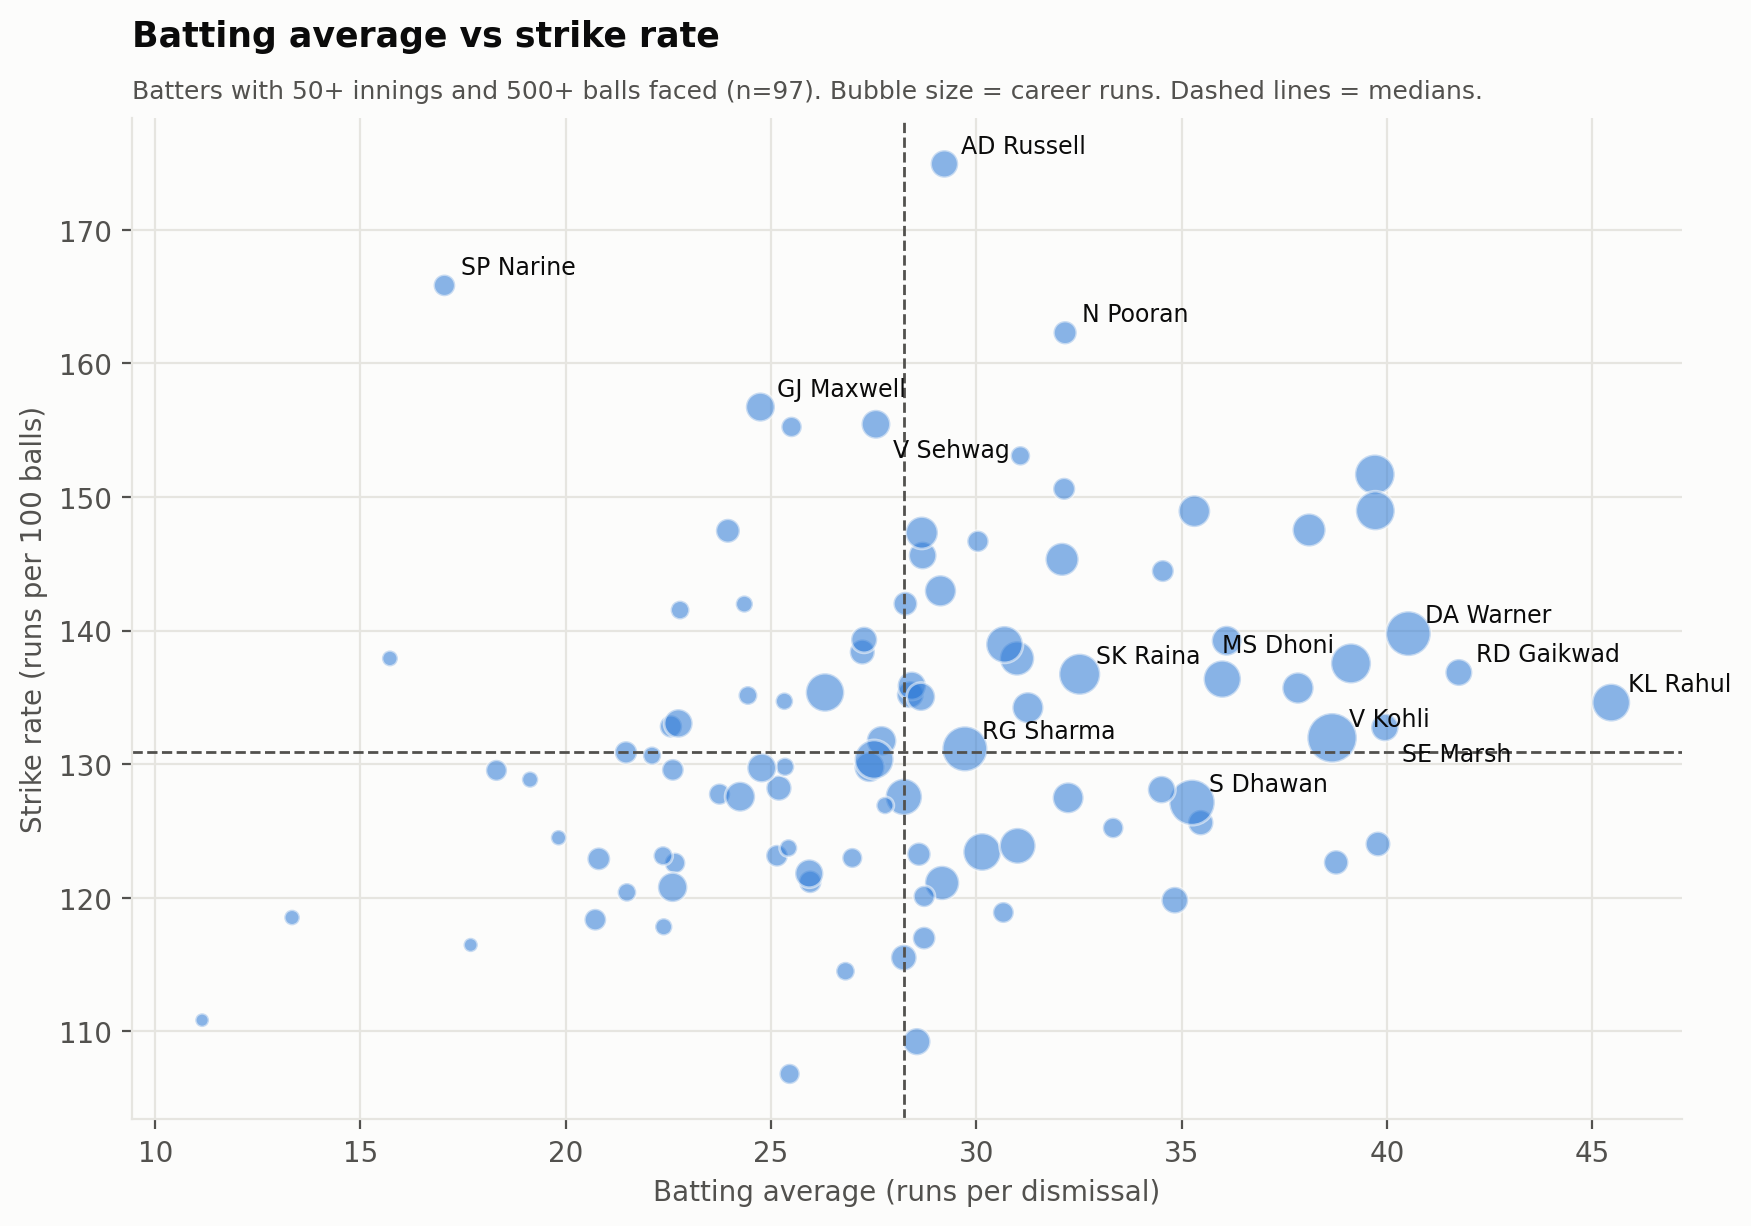

**Finding.** Among 123 batters with 500+ balls faced, AD Russell has the highest strike rate (174.93), then H Klaasen (168.31) and SP Narine (165.84). 12 of the top 15 were still playing in 2024, which fits the higher-scoring recent environment (not era-adjusted). In the scatter, 32 of 97 qualifying batters are above the median on both average and strike rate; the rank correlation between the two is 0.30.

**Limitation.** Not era-adjusted; recent careers benefit from the 2023-24 scoring environment.

In [16]:
show('C3')

### C4 · Batting consistency

In [17]:
show('C4')

**Question.** Which players score most consistently?

**Why it matters.** Selectors value reliable contributions, not only peak scores.

**Metric.** Per-innings runs distribution for batters with 50+ innings: pct_30_plus = innings with >= 30 runs / innings; pct_under_10 = innings < 10; median and std of innings scores.

,player,innings,mean_score,median_score,pct_30_plus,pct_under_10,std_score
0,RD Gaikwad,65,36.6,32.0,55.4,26.2,30.7
1,SE Marsh,69,35.9,32.0,53.6,21.7,28.8
2,DA Warner,184,35.7,33.0,52.2,28.3,29.0
3,KL Rahul,123,38.1,29.0,48.8,17.1,29.5
4,MEK Hussey,58,34.1,24.0,48.3,29.3,29.2
5,F du Plessis,138,33.1,29.0,47.8,23.2,25.3
6,SR Tendulkar,78,29.9,27.5,47.4,20.5,22.7
7,V Kohli,244,32.8,25.0,47.1,24.2,27.5
8,Shubman Gill,100,32.2,27.0,47.0,32.0,28.9
9,RR Pant,110,29.9,27.0,45.5,25.5,24.2


**Finding.** Consistency is measured as the share of innings with 30+ runs. RD Gaikwad reaches 30 in 55.4% of 65 innings, followed by SE Marsh (53.6%) and DA Warner (52.2%). Even the most consistent batters fail (under 10) in roughly a fifth to a third of innings (range in this top 15: 17.1-35.6%), which shows how volatile T20 batting is. In 15 of these 15 the median score is below the mean, showing a right-skewed score distribution (a few big innings lift the mean).

**Limitation.** Batting position (not in data) strongly affects opportunity to reach 30.

### C5 · Fours and sixes

**Question.** Which players contribute the most fours and sixes?

**Why it matters.** Boundary hitting is the main driver of T20 scoring rates.

**Metric.** is_four / is_six = batsman_runs == 4 / 6 (documented proxy). boundary_run_pct = (4 x fours + 6 x sixes) / runs x 100; balls_per_six = balls faced / sixes.

,player,innings,balls,sixes,fours,boundary_run_pct
127,CH Gayle,141,3333,357,405,75.8
480,RG Sharma,252,5054,281,599,61.6
635,V Kohli,244,6065,273,706,55.7
377,MS Dhoni,229,3812,252,363,56.5
31,AB de Villiers,170,3403,251,413,61.2
150,DA Warner,184,4697,236,663,62.0
280,KA Pollard,171,2316,223,218,64.8
40,AD Russell,105,1420,209,170,77.9
575,SV Samson,163,3180,206,352,59.8
549,SK Raina,200,4043,203,506,58.6


**Most fours**

,player,innings,balls,fours,sixes,boundary_run_pct
515,S Dhawan,221,5324,768,153,58.9
635,V Kohli,244,6065,706,273,55.7
150,DA Warner,184,4697,663,236,62.0
480,RG Sharma,252,5054,599,281,61.6
549,SK Raina,200,4043,506,203,58.6
197,G Gambhir,152,3404,492,59,55.1
504,RV Uthappa,197,3799,481,182,60.9
51,AM Rahane,171,3761,479,103,54.6
285,KD Karthik,234,3577,466,161,58.4
191,F du Plessis,138,3352,422,166,58.7


**Six-hitting frequency (min 500 balls)**

,player,balls,sixes,balls_per_six
40,AD Russell,1420,209,6.8
399,N Pooran,1090,127,8.6
326,LS Livingstone,578,66,8.8
211,H Klaasen,590,64,9.2
488,RM Patidar,503,54,9.3
127,CH Gayle,3333,357,9.3
564,SP Narine,925,97,9.5
560,SO Hetmyer,812,82,9.9
516,S Dube,1024,101,10.1
280,KA Pollard,2316,223,10.4


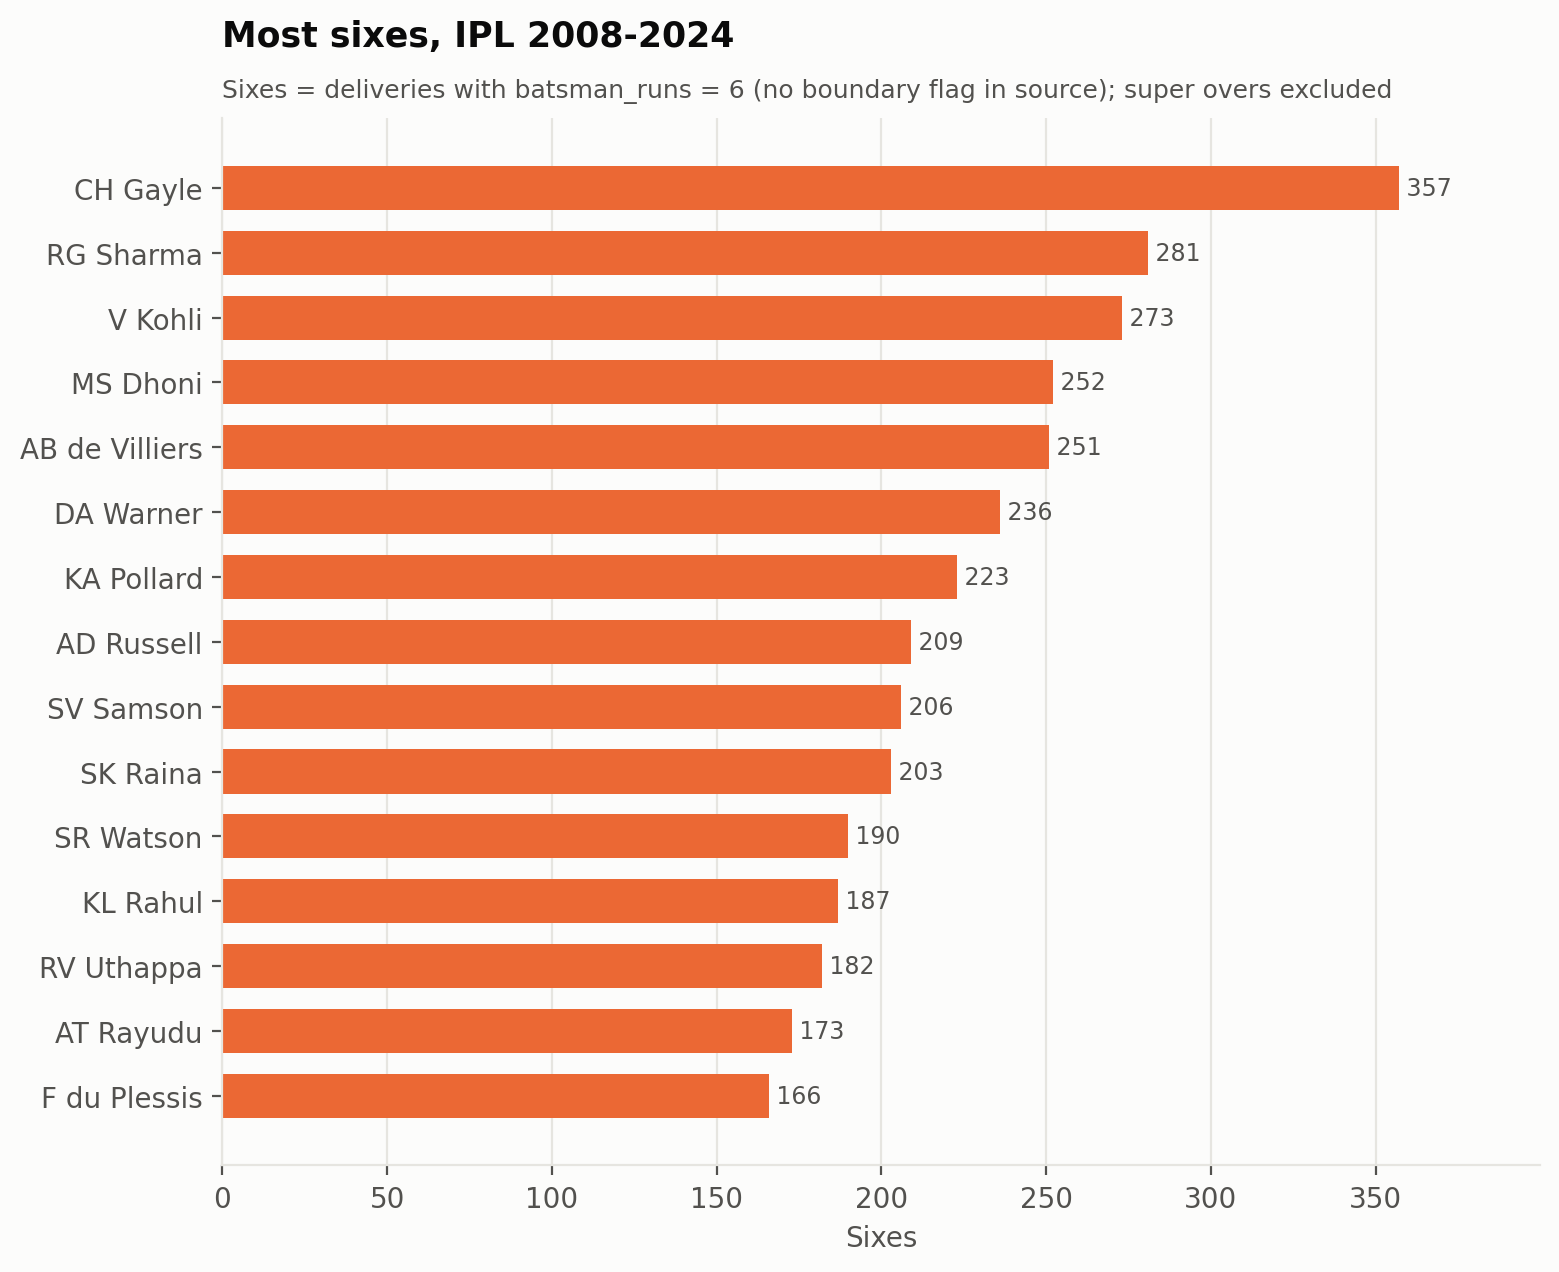

**Finding.** CH Gayle has the most sixes (357), ahead of RG Sharma (281) and V Kohli (273). S Dhawan has the most fours (768). By frequency (500+ balls), AD Russell hits a six every 6.8 balls. League-wide, sixes per match rose from 10.7 (2008) to 17.8 (2024).

**Limitation.** Proxy cannot distinguish an all-run four from a boundary (rare).

In [18]:
show('C5')

### C6 · Scoring by match phase

**Question.** How do scoring patterns differ between Powerplay, Middle Overs and Death Overs?

**Why it matters.** Phase-specific roles (openers, anchors, finishers) drive team selection and tactics.

**Metric.** Per phase: run rate = runs / legal balls x 6; dot % = is_dot_ball / legal balls; boundary % = (fours + sixes) / legal balls; balls per dismissal = legal balls / player outs.

,phase,runs,balls,outs,dots,fours,sixes,extras,run_rate,dot_pct,boundary_pct,balls_per_dismissal,share_of_runs_pct,overs_in_phase
0,Powerplay,102931,78656,3130,36951,12509,2945,6068,7.85,46.98,19.65,25.13,29.62,6
1,Middle,150655,116079,4994,37350,10537,5366,6627,7.79,32.18,13.70,23.24,43.36,9
2,Death,93884,56584,4784,16099,6781,4725,4977,9.96,28.45,20.33,11.83,27.02,5


**Fastest Powerplay scorers (min 300 balls)**

,player,runs,balls,sixes,strike_rate
0,SP Narine,946,552,55,171.4
1,Abhishek Sharma,758,482,35,157.3
2,YBK Jaiswal,1009,661,36,152.6
3,JM Bairstow,864,587,34,147.2
4,PP Shaw,1347,919,37,146.6
5,P Simran Singh,499,344,23,145.1
6,CA Lynn,779,540,37,144.3
7,V Sehwag,1593,1105,46,144.2
8,SA Yadav,859,609,27,141.1
9,RA Tripathi,977,693,36,141.0


**Fastest death-overs scorers (min 300 balls)**

,player,runs,balls,sixes,strike_rate
0,AB de Villiers,1868,838,140,222.9
1,RR Pant,923,454,67,203.3
2,JC Buttler,596,302,43,197.4
3,AD Russell,1324,681,118,194.4
4,SV Samson,780,410,53,190.2
5,V Kohli,1469,784,88,187.4
6,SO Hetmyer,791,437,58,181.0
7,RG Sharma,1513,836,91,181.0
8,GJ Maxwell,599,331,37,181.0
9,F du Plessis,568,314,28,180.9


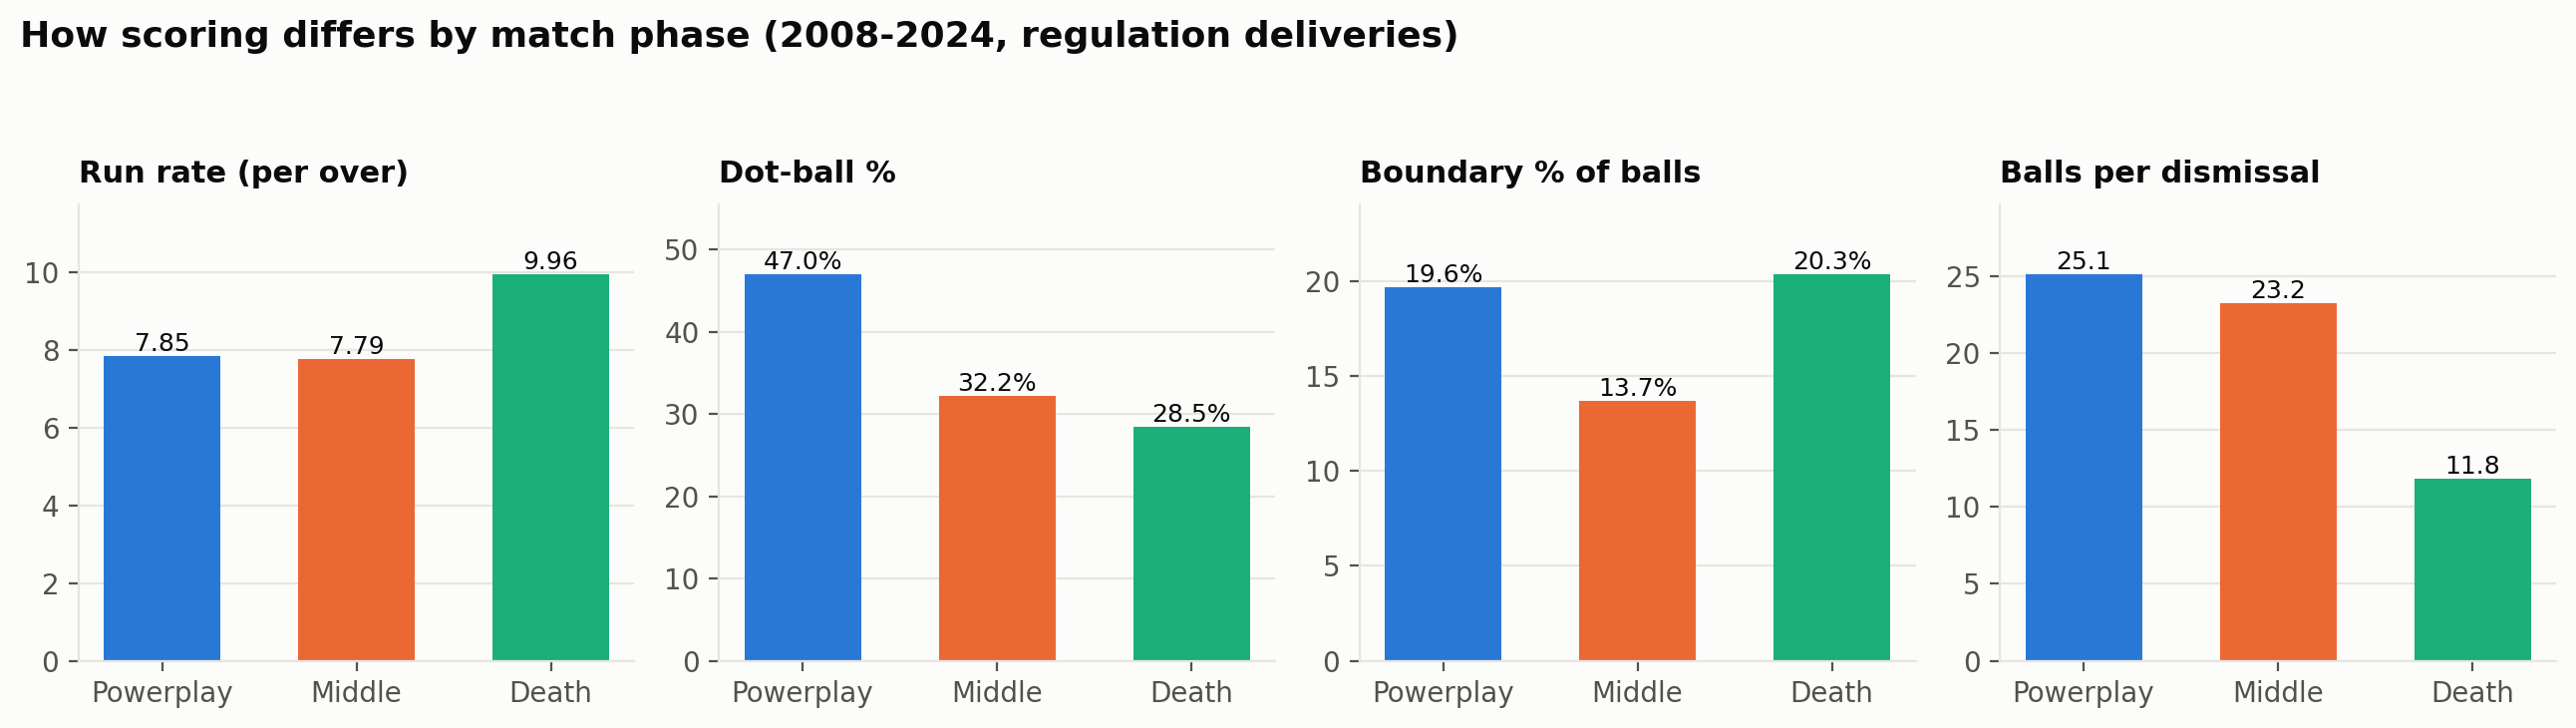

**Finding.** Death overs (16-20) score fastest (9.96/over) but cost a wicket every 11.8 balls, against 23.2 in the middle overs and 25.1 in the Powerplay. The Powerplay (7.85/over) combines the highest dot-ball % (47.0%) with a boundary % (19.6%) close to the death overs (20.3%): scoring comes in boundaries rather than singles while the field is restricted. The middle overs are the slowest (7.79/over) but contribute 43.4% of all runs because they are the longest phase. Fastest Powerplay scorer (300+ balls): SP Narine (SR 171.4); fastest death-overs scorer: AB de Villiers (SR 222.9).

**Limitation.** Phases use 20-over boundaries even in shortened matches (L10).

In [19]:
show('C6')

## D. Bowling analysis

### D1 · Leading wicket-takers

**Question.** Who are the leading bowler-credited wicket takers?

**Why it matters.** Wicket-taking is the primary measure of bowling impact.

**Metric.** wickets = sum(is_bowler_wicket): bowled, caught, caught and bowled, lbw, stumped, hit wicket.

,bowler,innings,overs,legal_balls,runs_conceded,wickets,economy,average,strike_rate,dot_pct
524,YS Chahal,159,586.5,3521,4602,205,7.84,22.45,17.18,33.91
348,PP Chawla,191,641.4,3850,5108,192,7.96,26.60,20.05,34.42
119,DJ Bravo,158,520.0,3120,4360,183,8.38,23.83,17.05,31.99
71,B Kumar,176,651.4,3910,4929,181,7.56,27.23,21.60,41.74
355,R Ashwin,208,754.0,4524,5369,180,7.12,29.83,25.13,34.31
446,SP Narine,175,679.1,4075,4571,180,6.73,25.39,22.64,38.50
8,A Mishra,162,561.5,3371,4145,174,7.38,23.82,19.37,35.15
438,SL Malinga,122,471.2,2828,3364,170,7.14,19.79,16.64,40.45
193,JJ Bumrah,133,508.5,3053,3715,165,7.30,22.52,18.50,40.03
373,RA Jadeja,211,638.1,3829,4864,160,7.62,30.40,23.93,31.76


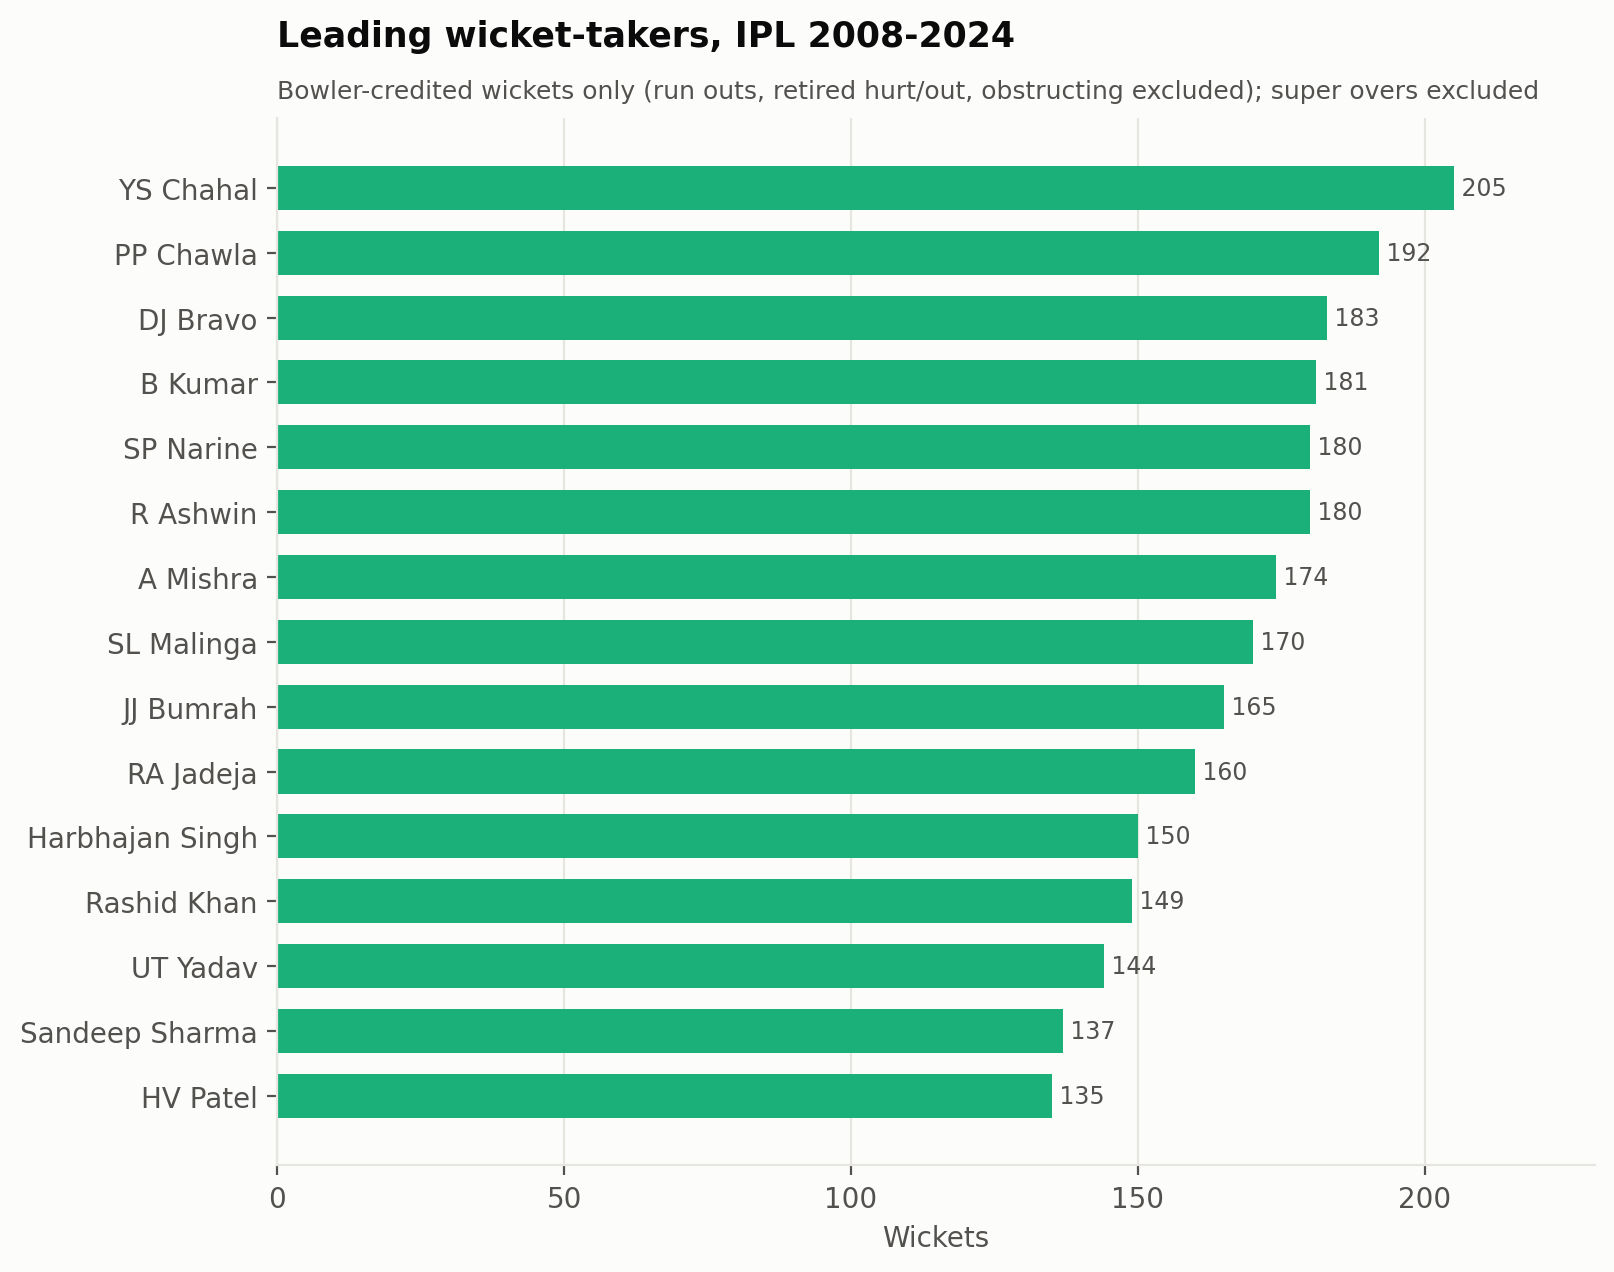

**Finding.** YS Chahal has the most bowler-credited wickets (205), followed by PP Chawla (192), DJ Bravo (183) and B Kumar (181). Using raw is_wicket instead would wrongly add run-outs and retirements to bowlers (see validation).

**Limitation.** Volume measure - rewards longevity.

In [20]:
show('D1')

### D2 · Economy rate

**Question.** Which bowlers have the best economy rates with a reasonable minimum legal-delivery threshold?

**Why it matters.** Economy captures run containment, critical in T20.

**Metric.** economy = bowler_runs_conceded / legal balls x 6 (byes, leg-byes and penalties not charged). Minimum 1000 legal balls.

,bowler,innings,overs,legal_balls,runs_conceded,wickets,economy,average,strike_rate,dot_pct
263,M Muralitharan,66,254.0,1524,1696,63,6.68,26.92,24.19,39.24
446,SP Narine,175,679.1,4075,4571,180,6.73,25.39,22.64,38.50
398,Rashid Khan,121,476.3,2859,3252,149,6.82,21.83,19.19,36.97
138,DW Steyn,95,362.4,2176,2508,97,6.92,25.86,22.43,46.83
163,Harbhajan Singh,160,569.2,3416,4030,150,7.08,26.87,22.77,36.97
355,R Ashwin,208,754.0,4524,5369,180,7.12,29.83,25.13,34.31
438,SL Malinga,122,471.2,2828,3364,170,7.14,19.79,16.64,40.45
259,M Kartik,55,191.3,1149,1388,31,7.25,44.77,37.06,33.25
437,SK Warne,54,199.0,1194,1447,57,7.27,25.39,20.95,35.68
42,AR Patel,148,516.3,3099,3758,123,7.28,30.55,25.20,32.88


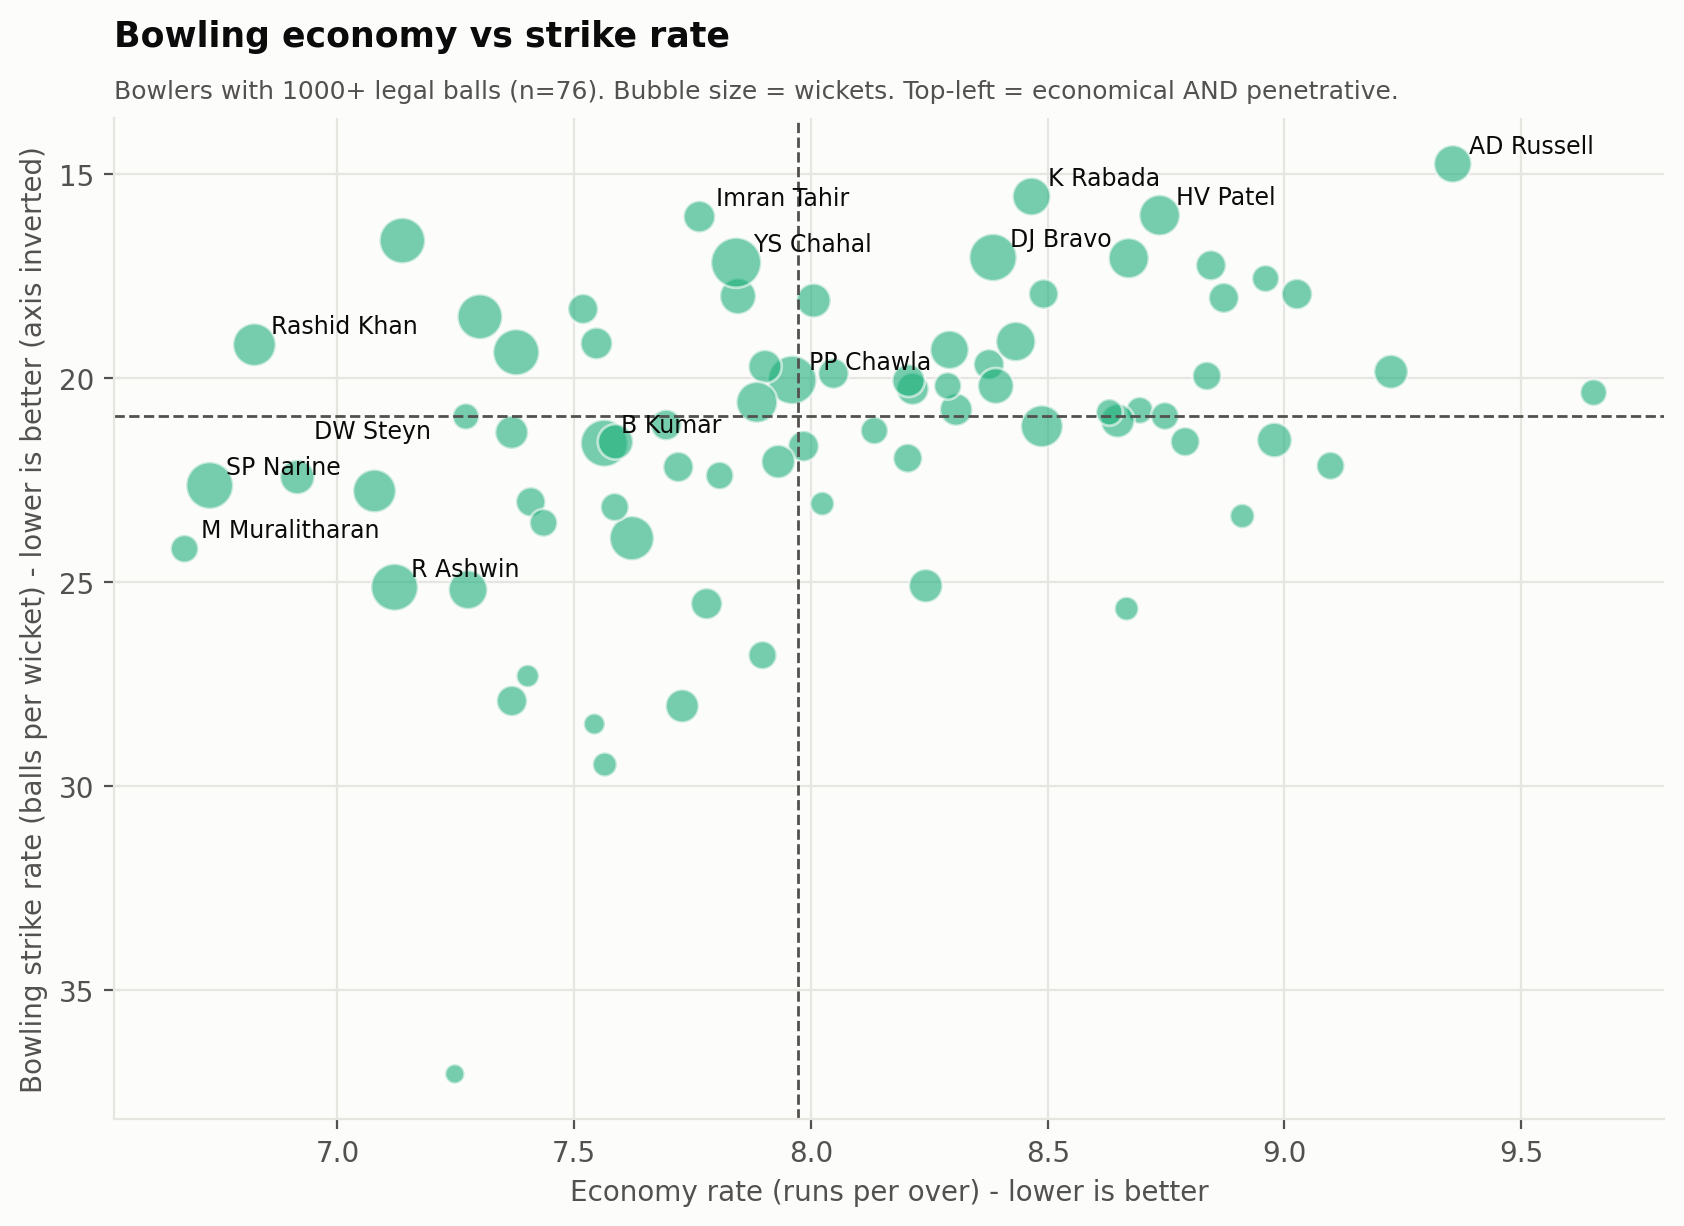

**Finding.** Among 76 bowlers with 1000+ legal balls, M Muralitharan has the best economy (6.68 runs/over), then SP Narine (6.73) and Rashid Khan (6.82). 10 of the top 15 bowled most of their balls before 2018, when scoring was lower - economy is not era-adjusted here. Of the more recent bowlers, Rashid Khan stands out (11% of balls before 2018).

**Limitation.** Era effect: older careers benefit from lower-scoring seasons.

In [21]:
show('D2')

### D3 · Bowling average and strike rate

**Question.** Which bowlers have the best bowling averages and strike rates?

**Why it matters.** Average = cost per wicket; strike rate = frequency of wickets.

**Metric.** average = bowler_runs_conceded / wickets; strike_rate = legal balls / wickets. Minimum 1000 legal balls.

,bowler,innings,overs,legal_balls,runs_conceded,wickets,economy,average,strike_rate,dot_pct
438,SL Malinga,122,471.2,2828,3364,170,7.14,19.79,16.64,40.45
174,Imran Tahir,59,219.2,1316,1703,82,7.76,20.77,16.05,33.21
398,Rashid Khan,121,476.3,2859,3252,149,6.82,21.83,19.19,36.97
212,K Rabada,80,303.2,1820,2568,117,8.47,21.95,15.56,39.18
524,YS Chahal,159,586.5,3521,4602,205,7.84,22.45,17.18,33.91
193,JJ Bumrah,133,508.5,3053,3715,165,7.30,22.52,18.50,40.03
289,MM Patel,63,225.5,1355,1698,74,7.52,22.95,18.31,43.54
29,AD Russell,112,282.5,1697,2646,115,9.36,23.01,14.76,34.41
162,HV Patel,103,360.2,2162,3148,135,8.74,23.32,16.01,32.84
10,A Nehra,88,318.0,1908,2495,106,7.85,23.54,18.00,41.82


**Best bowling strike rate**

,bowler,innings,overs,legal_balls,runs_conceded,wickets,economy,average,strike_rate,dot_pct
29,AD Russell,112,282.5,1697,2646,115,9.36,23.01,14.76,34.41
212,K Rabada,80,303.2,1820,2568,117,8.47,21.95,15.56,39.18
162,HV Patel,103,360.2,2162,3148,135,8.74,23.32,16.01,32.84
174,Imran Tahir,59,219.2,1316,1703,82,7.76,20.77,16.05,33.21
438,SL Malinga,122,471.2,2828,3364,170,7.14,19.79,16.64,40.45
119,DJ Bravo,158,520.0,3120,4360,183,8.38,23.83,17.05,31.99
290,MM Sharma,111,375.3,2253,3256,132,8.67,24.67,17.07,34.71
524,YS Chahal,159,586.5,3521,4602,205,7.84,22.45,17.18,33.91
223,KK Ahmed,57,212.4,1276,1881,74,8.84,25.42,17.24,40.13
12,A Nortje,46,175.4,1054,1574,60,8.96,26.23,17.57,38.05


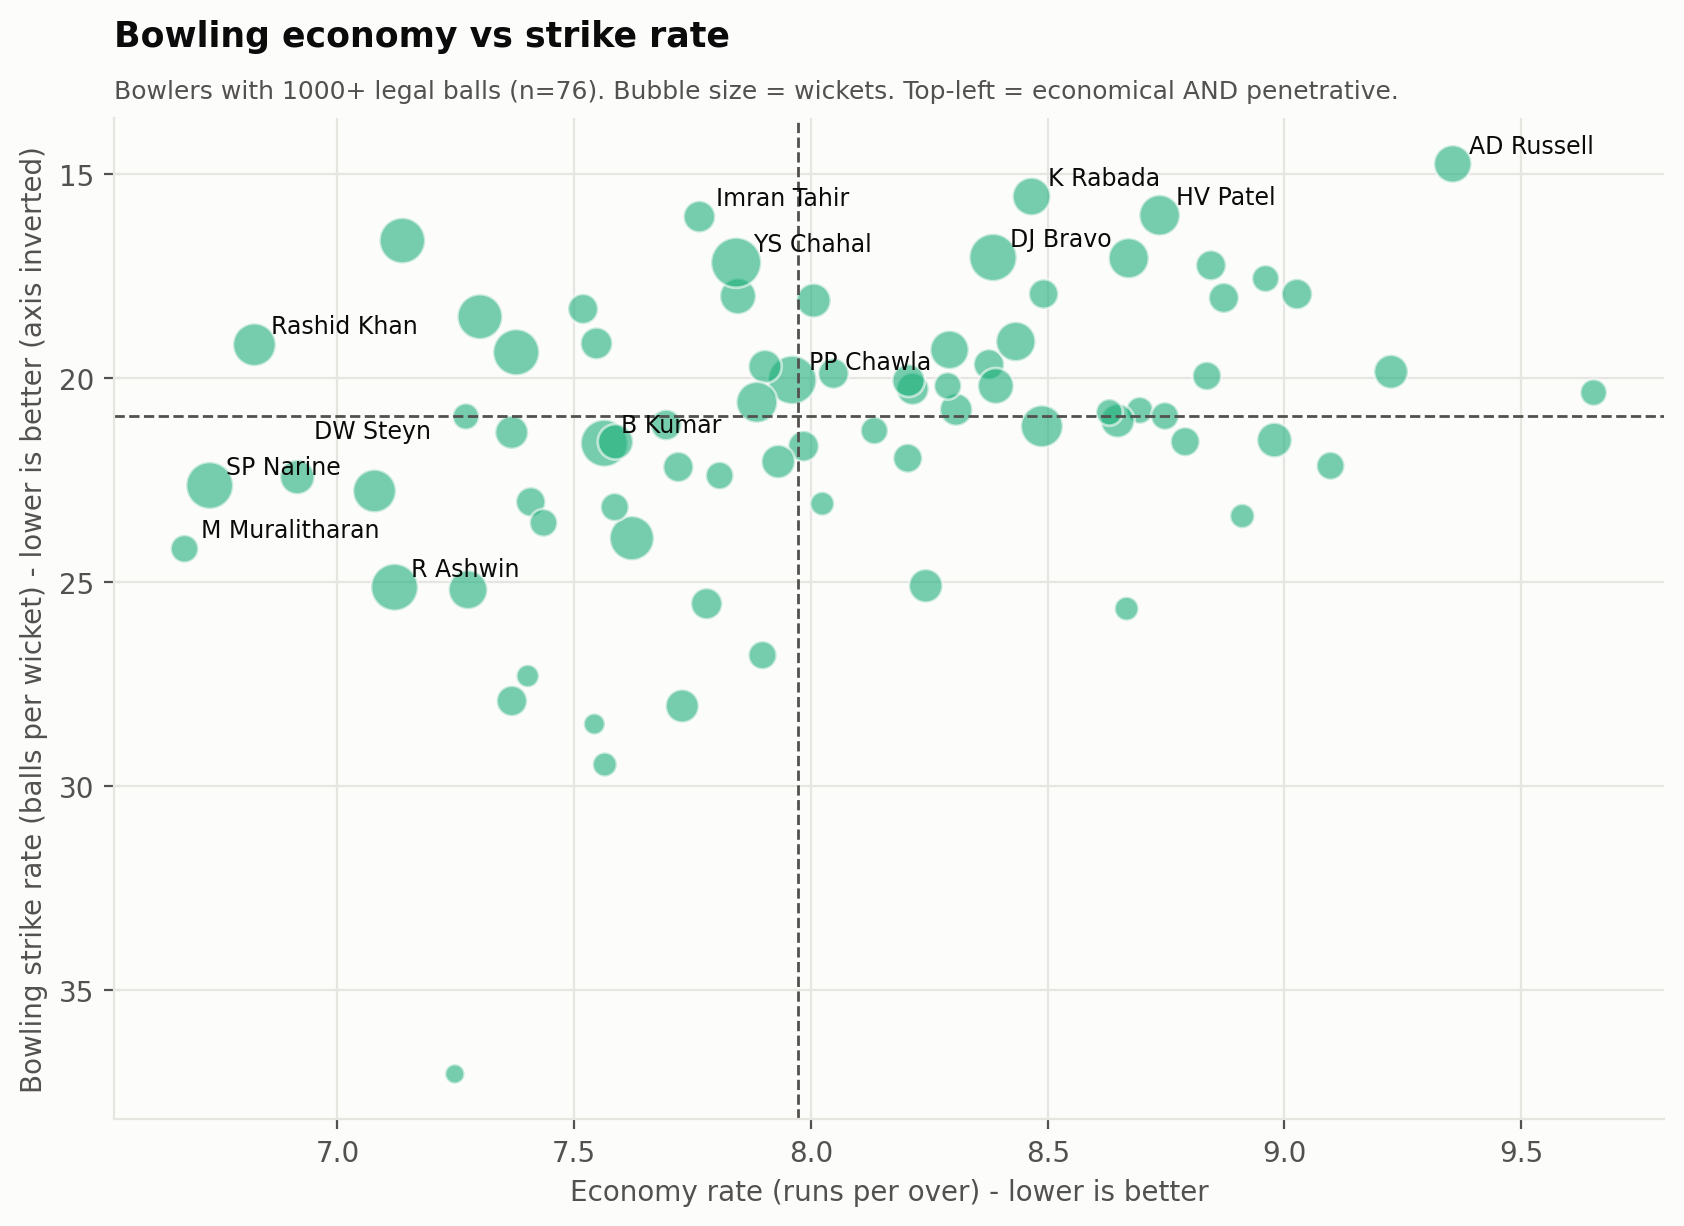

**Finding.** Best bowling average: SL Malinga (19.79 runs per wicket), then Imran Tahir (20.77). Best strike rate: AD Russell (14.76 balls per wicket), then K Rabada (15.56). The scatter separates containing bowlers (low economy) from wicket-takers (low strike rate); bowlers strong on both appear in the top-left quadrant.

**Limitation.** Not era-adjusted.

In [22]:
show('D3')

### D4 · Phase bowling

In [23]:
show('D4')

**Question.** Which bowlers perform best in different match phases?

**Why it matters.** Teams pick bowlers for specific phases (new ball, middle, death).

**Metric.** Bowler economy/strike rate computed within each phase; minimum 600 legal balls in that phase.

,bowler,legal_balls,runs_conceded,wickets,economy,strike_rate,dot_pct
361,SL Malinga,1111,1159,37,6.26,30.03,52.39
109,DW Steyn,1134,1184,34,6.26,33.35,55.03
59,B Kumar,2153,2293,72,6.39,29.90,54.16
158,JJ Bumrah,1032,1131,34,6.58,30.35,52.13
282,P Kumar,1572,1754,40,6.69,39.30,51.65
431,Z Khan,1292,1452,52,6.74,24.85,49.30
368,SP Narine,918,1048,27,6.85,34.00,47.39
297,R Ashwin,1198,1368,49,6.85,24.45,43.49
242,MM Patel,654,762,29,6.99,22.55,53.21
379,Sandeep Sharma,1614,1881,60,6.99,26.90,48.88


**Middle overs**

,bowler,legal_balls,runs_conceded,wickets,economy,strike_rate,dot_pct
428,SP Narine,2136,2263,80,6.36,26.70,35.63
383,Rashid Khan,2025,2146,96,6.36,21.09,36.89
255,M Muralitharan,1105,1174,39,6.37,28.33,38.19
7,A Kumble,690,758,25,6.59,27.60,36.52
356,R Sharma,684,759,30,6.66,22.80,36.99
187,JJ Bumrah,774,861,40,6.67,19.35,38.50
420,SK Warne,942,1065,38,6.78,24.79,36.62
337,PP Ojha,1373,1567,63,6.85,21.79,35.98
494,Washington Sundar,612,701,20,6.87,30.60,29.41
157,Harbhajan Singh,2370,2737,94,6.93,25.21,33.42


**Death overs**

,bowler,legal_balls,runs_conceded,wickets,economy,strike_rate,dot_pct
373,SP Narine,1021,1260,73,7.40,13.99,36.53
365,SL Malinga,1117,1464,108,7.86,10.34,31.33
162,JJ Bumrah,1247,1723,91,8.29,13.70,30.95
118,DW Steyn,634,877,50,8.30,12.68,34.38
81,CH Morris,646,933,58,8.67,11.14,28.33
442,Z Khan,607,916,37,9.05,16.41,24.55
62,B Kumar,1353,2074,100,9.20,13.53,26.46
437,YS Chahal,613,953,59,9.33,10.39,28.55
102,DJ Bravo,1385,2161,115,9.36,12.04,28.74
134,HV Patel,751,1254,73,10.02,10.29,30.49


**Finding.** With 600+ legal balls in the phase: best Powerplay economy - SL Malinga (6.26); best middle-overs economy - SP Narine (6.36); best death-overs economy - SP Narine (7.40), then SL Malinga (7.86). The median economy of the 10 best death bowlers (8.86) is 2.14 runs/over higher than the 10 best Powerplay bowlers (6.71), matching the league phase profile (C6). Narine and Malinga appear in more than one phase list.

**Limitation.** Phase boundaries fixed at 20-over values (L10).

### D5 · Bowling patterns across seasons

**Question.** How do wicket-taking and run-conceding patterns vary across seasons?

**Why it matters.** Gives the league context needed to judge any bowler's numbers.

**Metric.** economy = all runs / legal balls x 6 (team view, incl. extras); bowling_sr = legal balls / bowler wickets; dot % = is_dot_ball / legal balls.

,season_year,economy,bowling_sr,dot_pct,bowler_wickets,player_outs
0,2008,8.31,21.44,37.96,604,689
1,2009,7.48,21.07,39.11,621,697
2,2010,8.13,22.22,35.84,627,720
3,2011,7.73,22.23,38.25,739,813
4,2012,7.83,22.29,36.27,772,857
5,2013,7.68,21.25,38.35,829,909
6,2014,8.20,22.83,36.27,606,671
7,2015,8.37,21.06,36.31,624,686
8,2016,8.31,23.04,34.14,591,665
9,2017,8.41,20.60,33.96,650,708


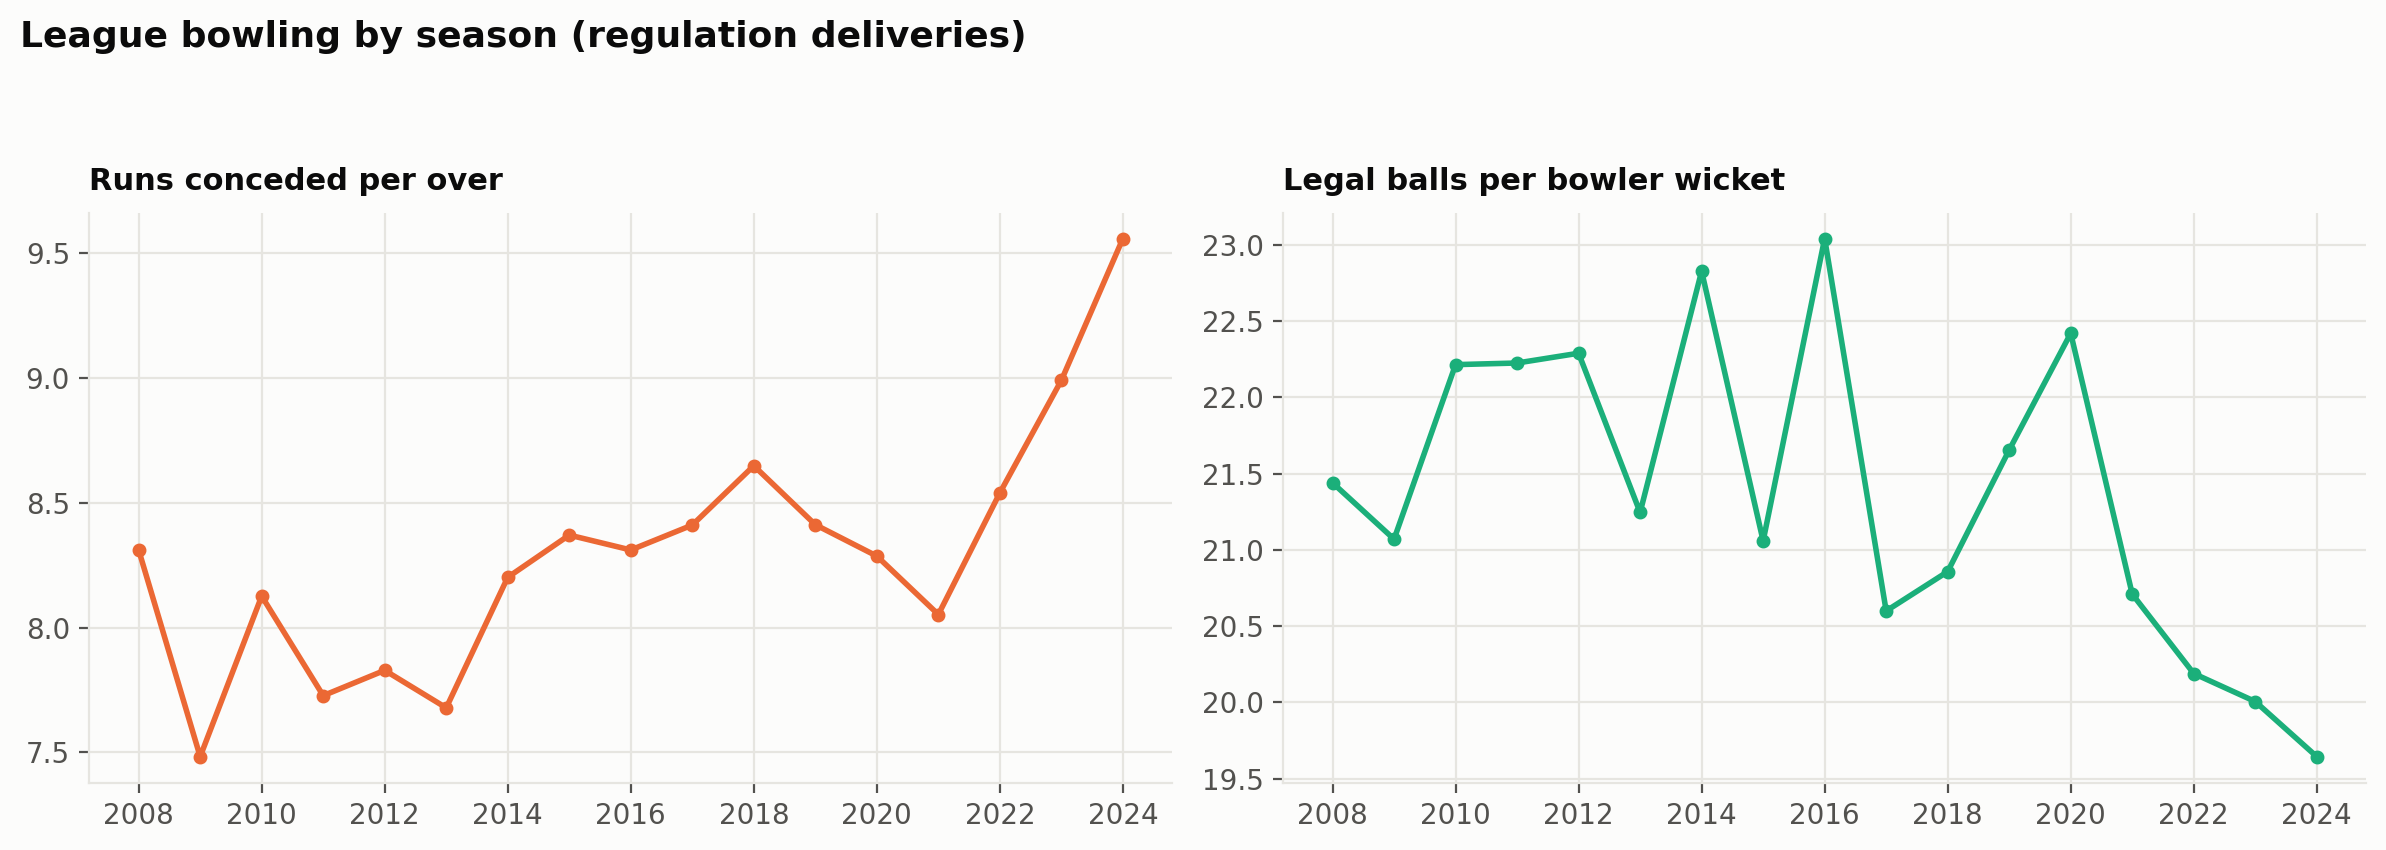

**Finding.** League economy ranged from 7.48 (2009) to 9.56 (2024), a 28% spread. Balls per bowler wicket ranged from 19.6 to 23.0 (a 17% spread), so wicket frequency varied less than run-conceding. Dot-ball % fell from 38.0% (2008) to 32.9% (2024).

In [24]:
show('D5')

## E. Match & venue insights

### E1 · Toss impact

**Question.** Does winning the toss correlate with winning the match?

**Why it matters.** Tests a widely held belief and informs how much to read into toss results.

**Metric.** toss_winner_won over decided matches (no-results excluded; super-over winners count). 95% CI via normal approximation to the binomial.

,metric,value
0,Decided matches,1090.00
1,Toss winner won %,50.83
2,95% CI low,47.86
3,95% CI high,53.79
4,Won % when choosing to bat,45.38
5,Won % when choosing to field,53.86
6,Chose to field %,64.29


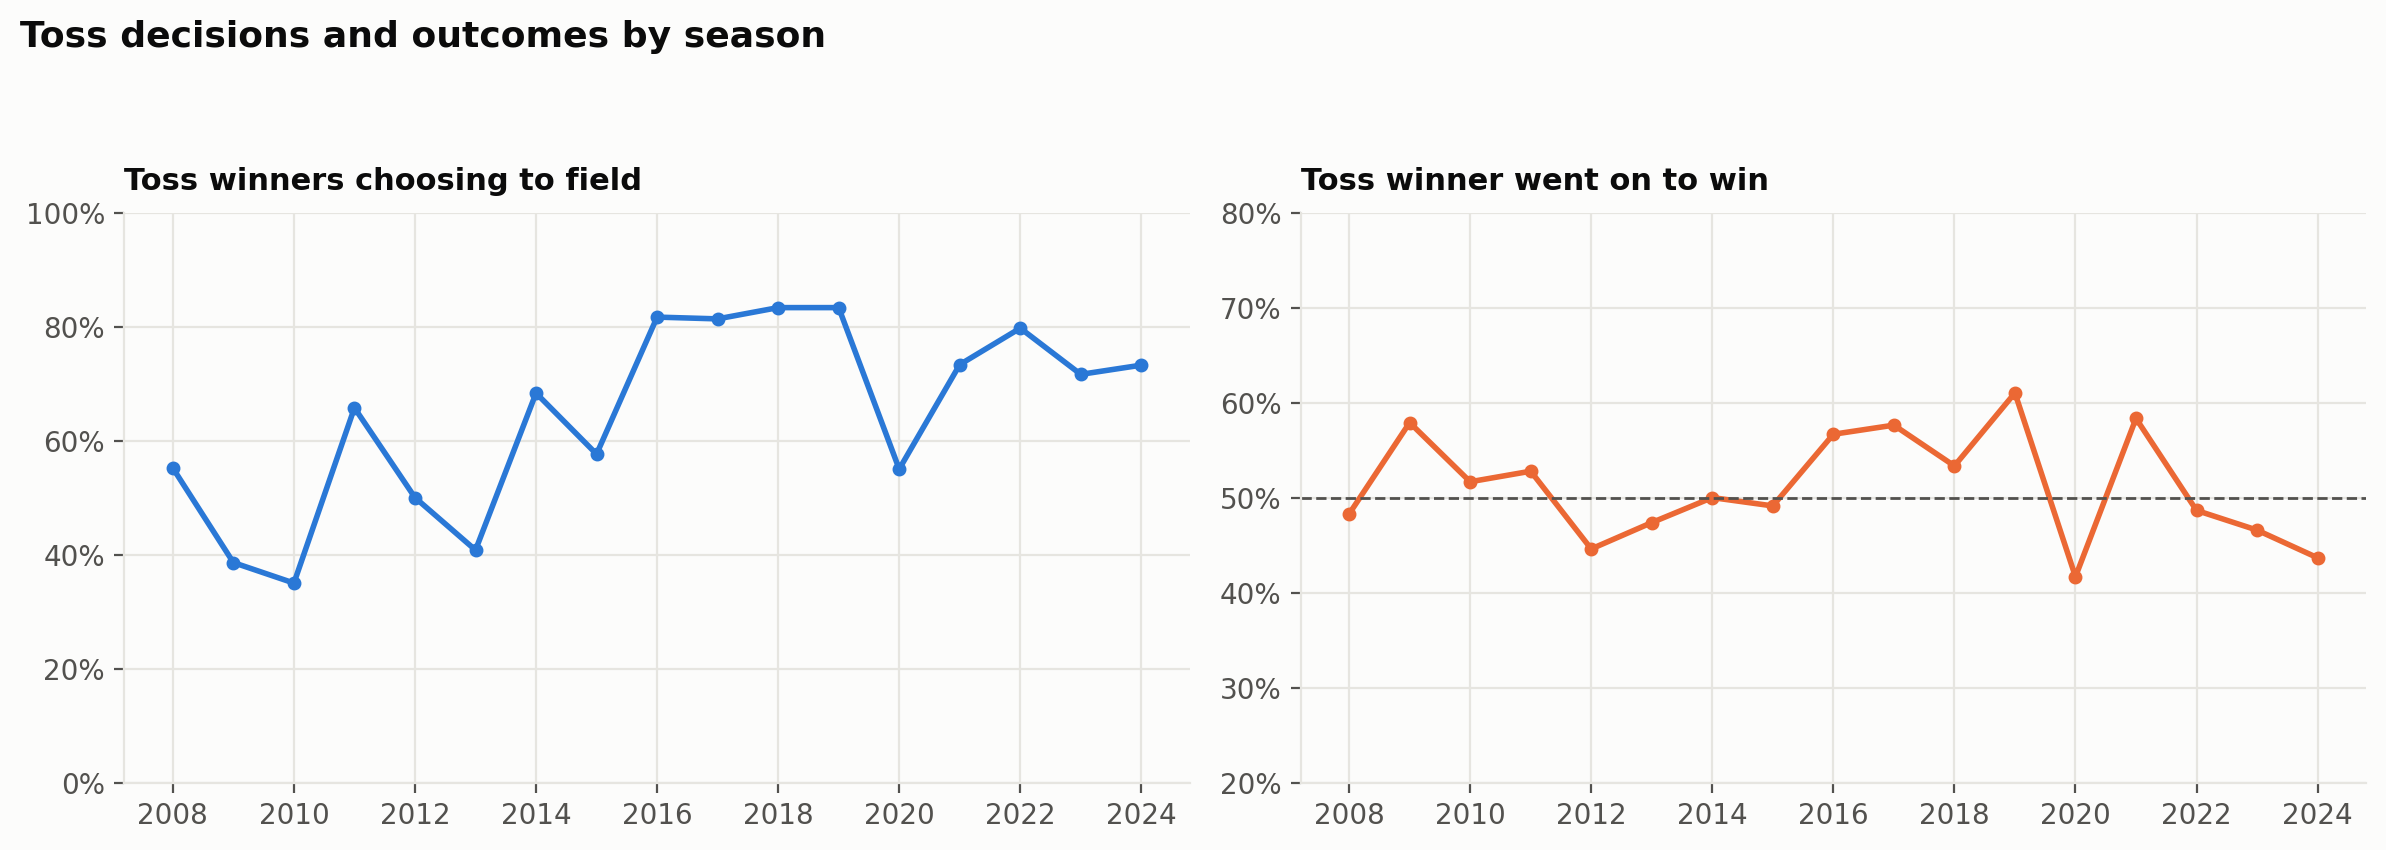

**Finding.** The toss winner won 50.8% of 1090 decided matches (95% CI 47.9-53.8%). The interval includes 50%, so across the whole period the toss shows no statistically clear advantage. Teams increasingly choose to field: 55% in 2008 vs 73% in 2024 (peak 83%). Toss winners who chose to field won 53.9% vs 45.4% when choosing to bat. This is association only: the toss decision is itself a strategic choice influenced by conditions.

**Limitation.** Observational; no causal claim.

In [25]:
show('E1')

### E2 · Batting first vs chasing

**Question.** How often do teams win batting first versus chasing?

**Why it matters.** Underpins the toss decision and team strategy.

**Metric.** Share of matches with result_for == 'chasing' among matches with result_for in {batting first, chasing}.

,season_year,matches,chase_wins,chase_win_pct
0,2008,58,36,62.1
1,2009,56,30,53.6
2,2010,59,28,47.5
3,2011,72,40,55.6
4,2012,74,40,54.1
5,2013,74,37,50.0
6,2014,59,37,62.7
7,2015,56,24,42.9
8,2016,60,41,68.3
9,2017,58,32,55.2


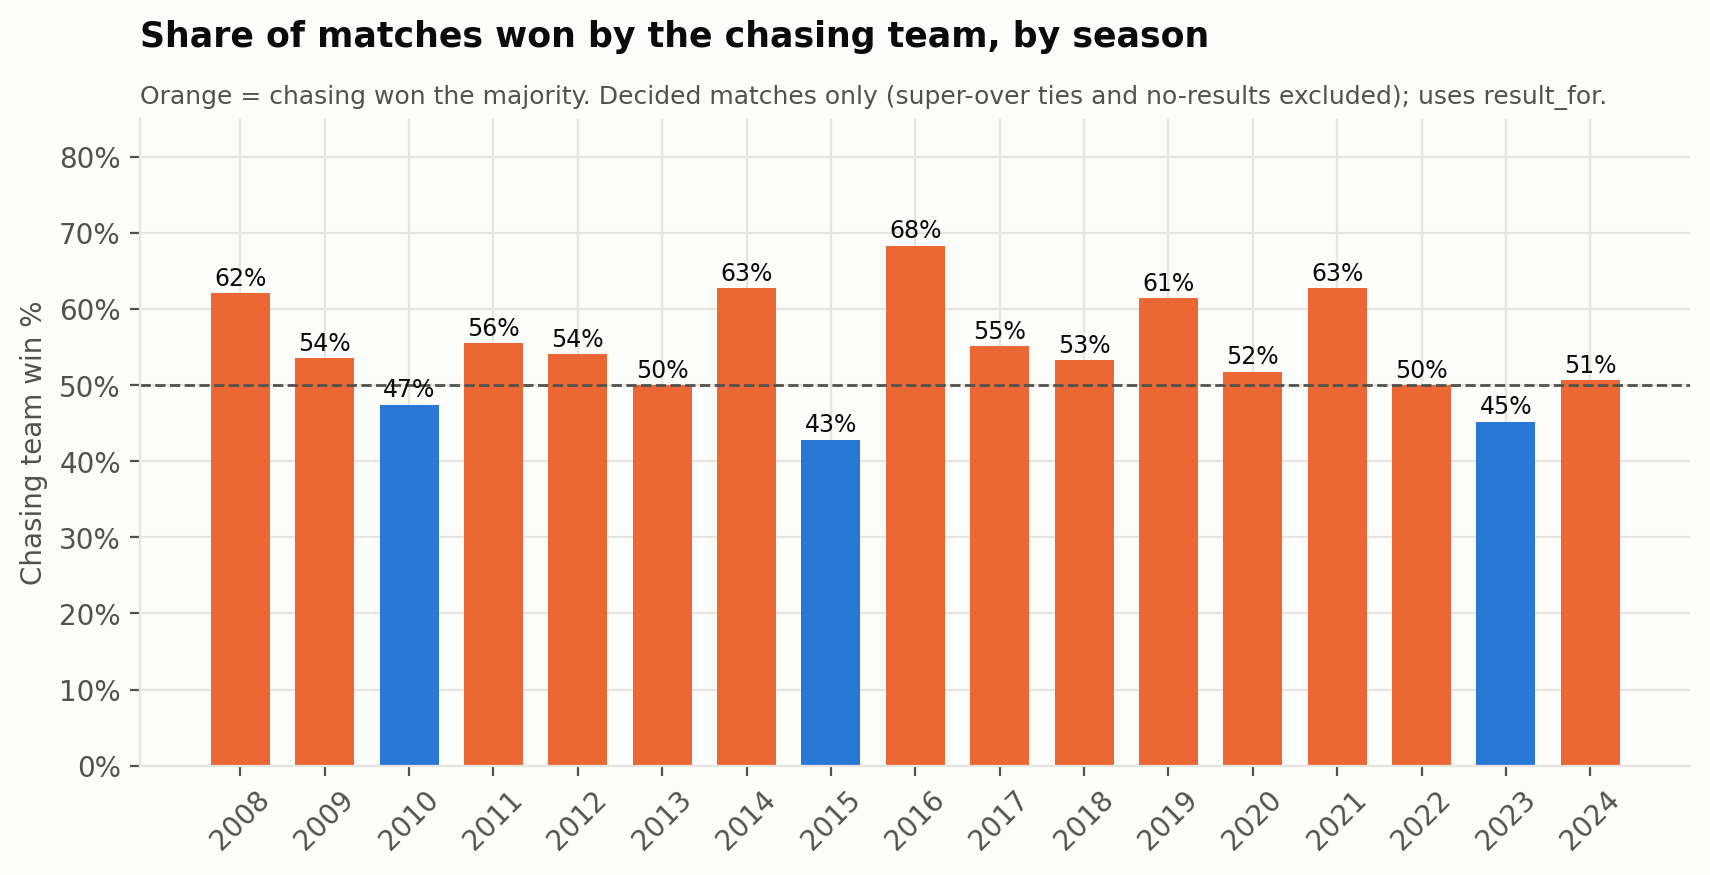

**Finding.** Chasing teams won 54.3% of 1076 decided matches (95% CI 51.3-57.3%); excluding the 21 D/L matches gives 53.9%. Chasing won the majority in 12 of 17 seasons; the strongest chasing season was 2016 (68.3%), while batting first won the majority in 2010, 2015, 2023.

**Limitation.** D/L matches included via result_for; sensitivity without them reported.

In [26]:
show('E2')

### E3 · Venue first-innings scores

**Question.** Which venues have the highest average first-innings scores?

**Why it matters.** Venue 'par scores' inform team strategy and fan expectations.

**Metric.** Full matches per venue; avg_inn1 = mean inn1_runs; avg_inn1_vs_season = mean(inn1_runs - season mean). Minimum 20 full matches.

,venue,city,full_matches,first_season,last_season,avg_inn1,avg_inn1_vs_season,run_rate
4,Brabourne Stadium,Mumbai,27,2010,2022,178.5,9.7,8.9
16,M Chinnaswamy Stadium,Bengaluru,85,2008,2024,177.2,9.8,8.8
0,Arun Jaitley Stadium,Delhi,86,2008,2024,171.2,4.8,8.5
20,Narendra Modi Stadium,Ahmedabad,35,2010,2024,170.3,-4.2,8.6
35,Wankhede Stadium,Mumbai,118,2008,2024,170.3,3.0,8.6
25,Punjab Cricket Association IS Bindra Stadium,Chandigarh,59,2008,2023,168.9,4.3,8.5
10,Eden Gardens,Kolkata,86,2008,2024,168.9,1.4,8.5
17,MA Chidambaram Stadium,Chennai,85,2008,2024,163.9,-2.9,8.0
26,Rajiv Gandhi International Stadium,Hyderabad,75,2008,2024,163.8,-3.8,8.2
9,Dubai International Cricket Stadium,Dubai,46,2014,2021,163.8,-2.0,8.0


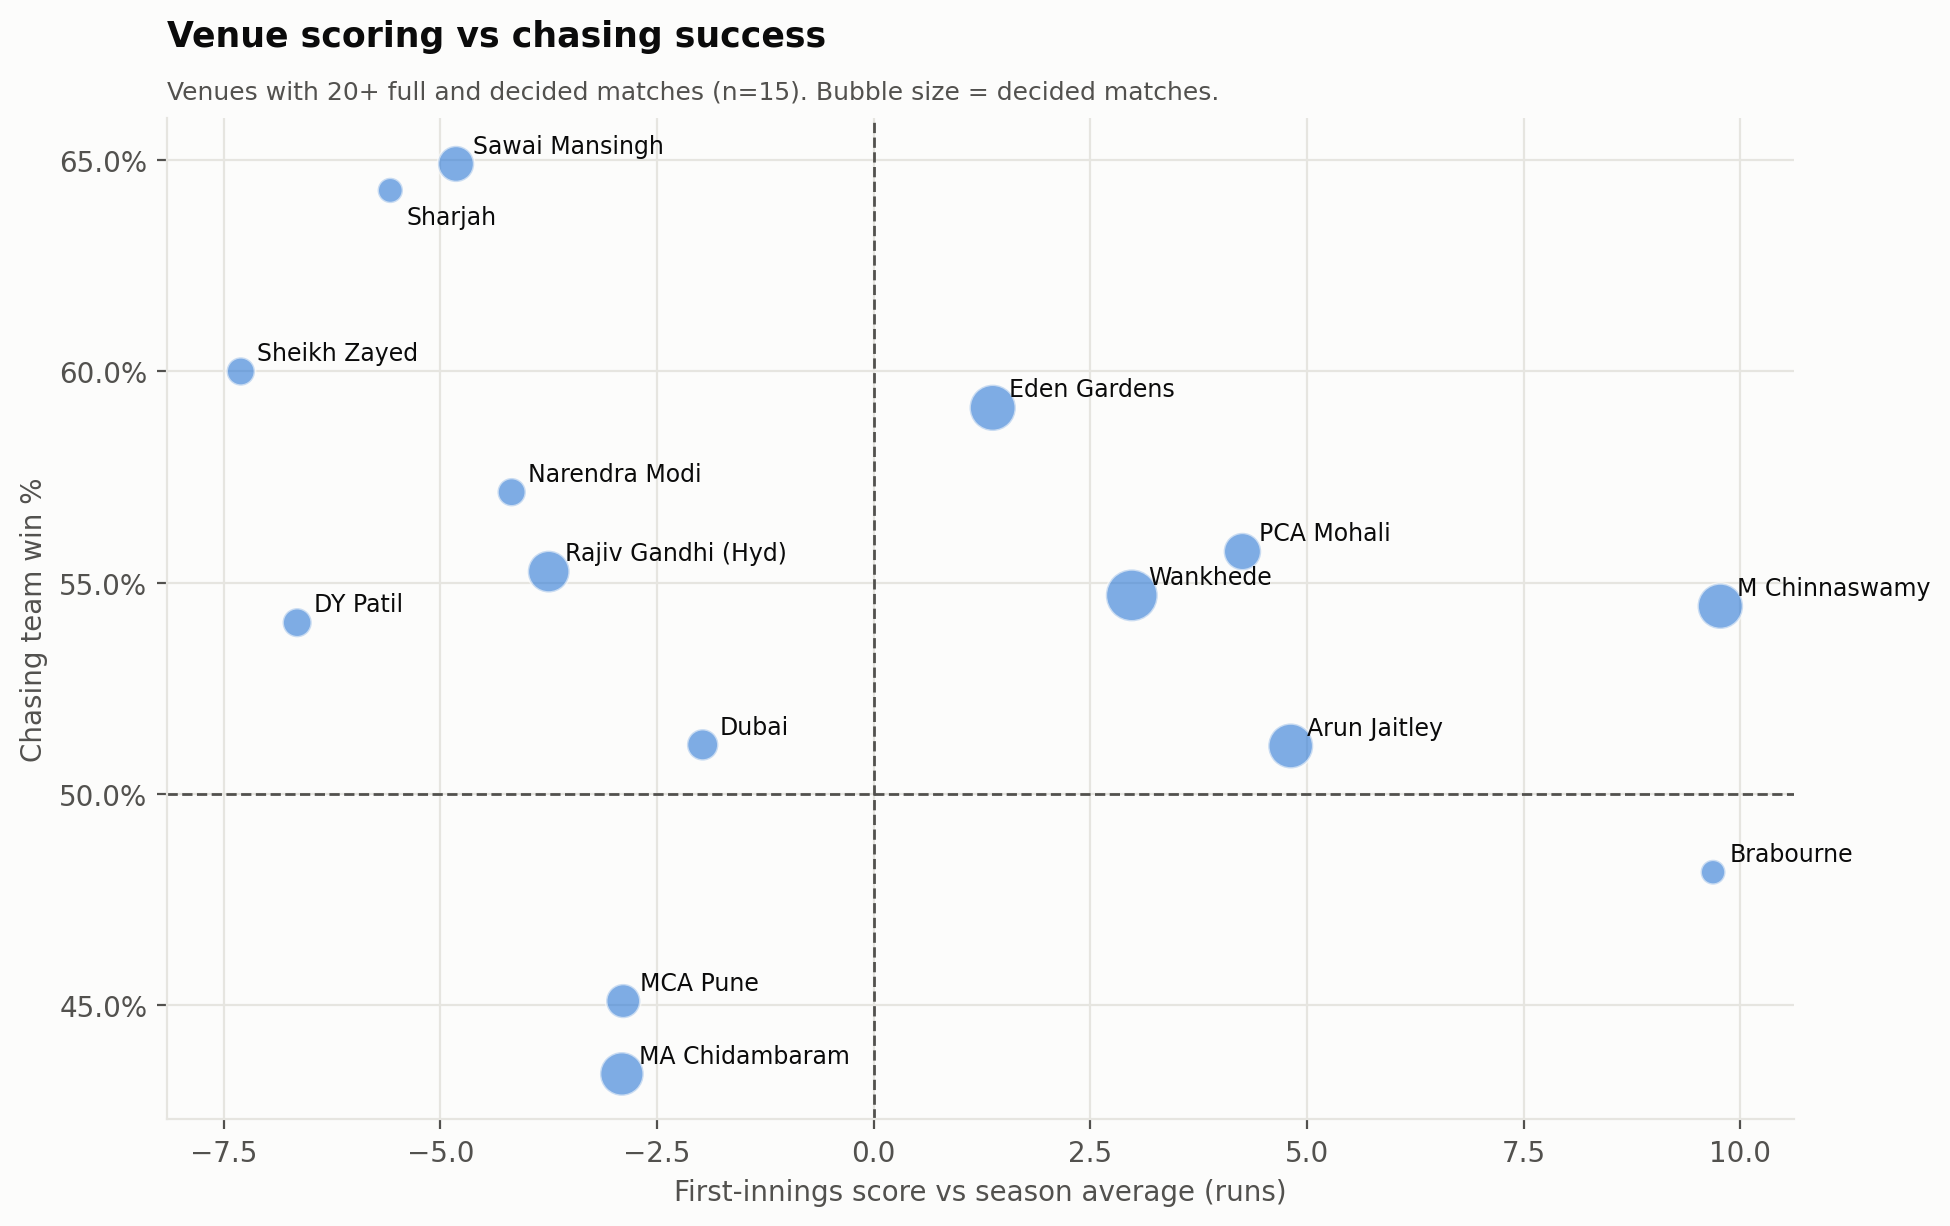

**Finding.** Of 15 venues with 20+ full matches, Brabourne Stadium has the highest average first-innings score (178.5), and Sheikh Zayed Stadium the lowest (158.9). Raw venue averages can be confounded by which seasons a venue hosted (e.g. Narendra Modi Stadium ranks 4 of 15 raw but is -4.2 vs its seasons' averages). Adjusted for season, the highest-scoring venue is M Chinnaswamy Stadium (+9.8 runs vs season average) and the lowest is Sheikh Zayed Stadium (-7.3).

**Limitation.** Venues hosted different eras; use the season-adjusted column for fair comparison.

In [27]:
show('E3')

### E4 · Venue chasing success

**Question.** Which venues have the strongest chasing success rates?

**Why it matters.** Helps decide whether to bat or field after winning the toss at a given ground.

**Metric.** chase_win_pct = chasing wins / matches with result_for in {batting first, chasing} at the venue. Minimum 20 decided matches.

,venue,city,decided,chase_wins,chase_win_pct,ci_low,ci_high
28,Sawai Mansingh Stadium,Jaipur,57,37,64.9,52.5,77.3
30,Sharjah Cricket Stadium,Sharjah,28,18,64.3,46.5,82.0
31,Sheikh Zayed Stadium,Abu Dhabi,35,21,60.0,43.8,76.2
10,Eden Gardens,Kolkata,93,55,59.1,49.1,69.1
20,Narendra Modi Stadium,Ahmedabad,35,20,57.1,40.7,73.5
25,Punjab Cricket Association IS Bindra Stadium,Chandigarh,61,34,55.7,43.3,68.2
26,Rajiv Gandhi International Stadium,Hyderabad,76,42,55.3,44.1,66.4
35,Wankhede Stadium,Mumbai,117,64,54.7,45.7,63.7
16,M Chinnaswamy Stadium,Bengaluru,90,49,54.4,44.2,64.7
7,Dr DY Patil Sports Academy,Navi Mumbai,37,20,54.1,38.0,70.1


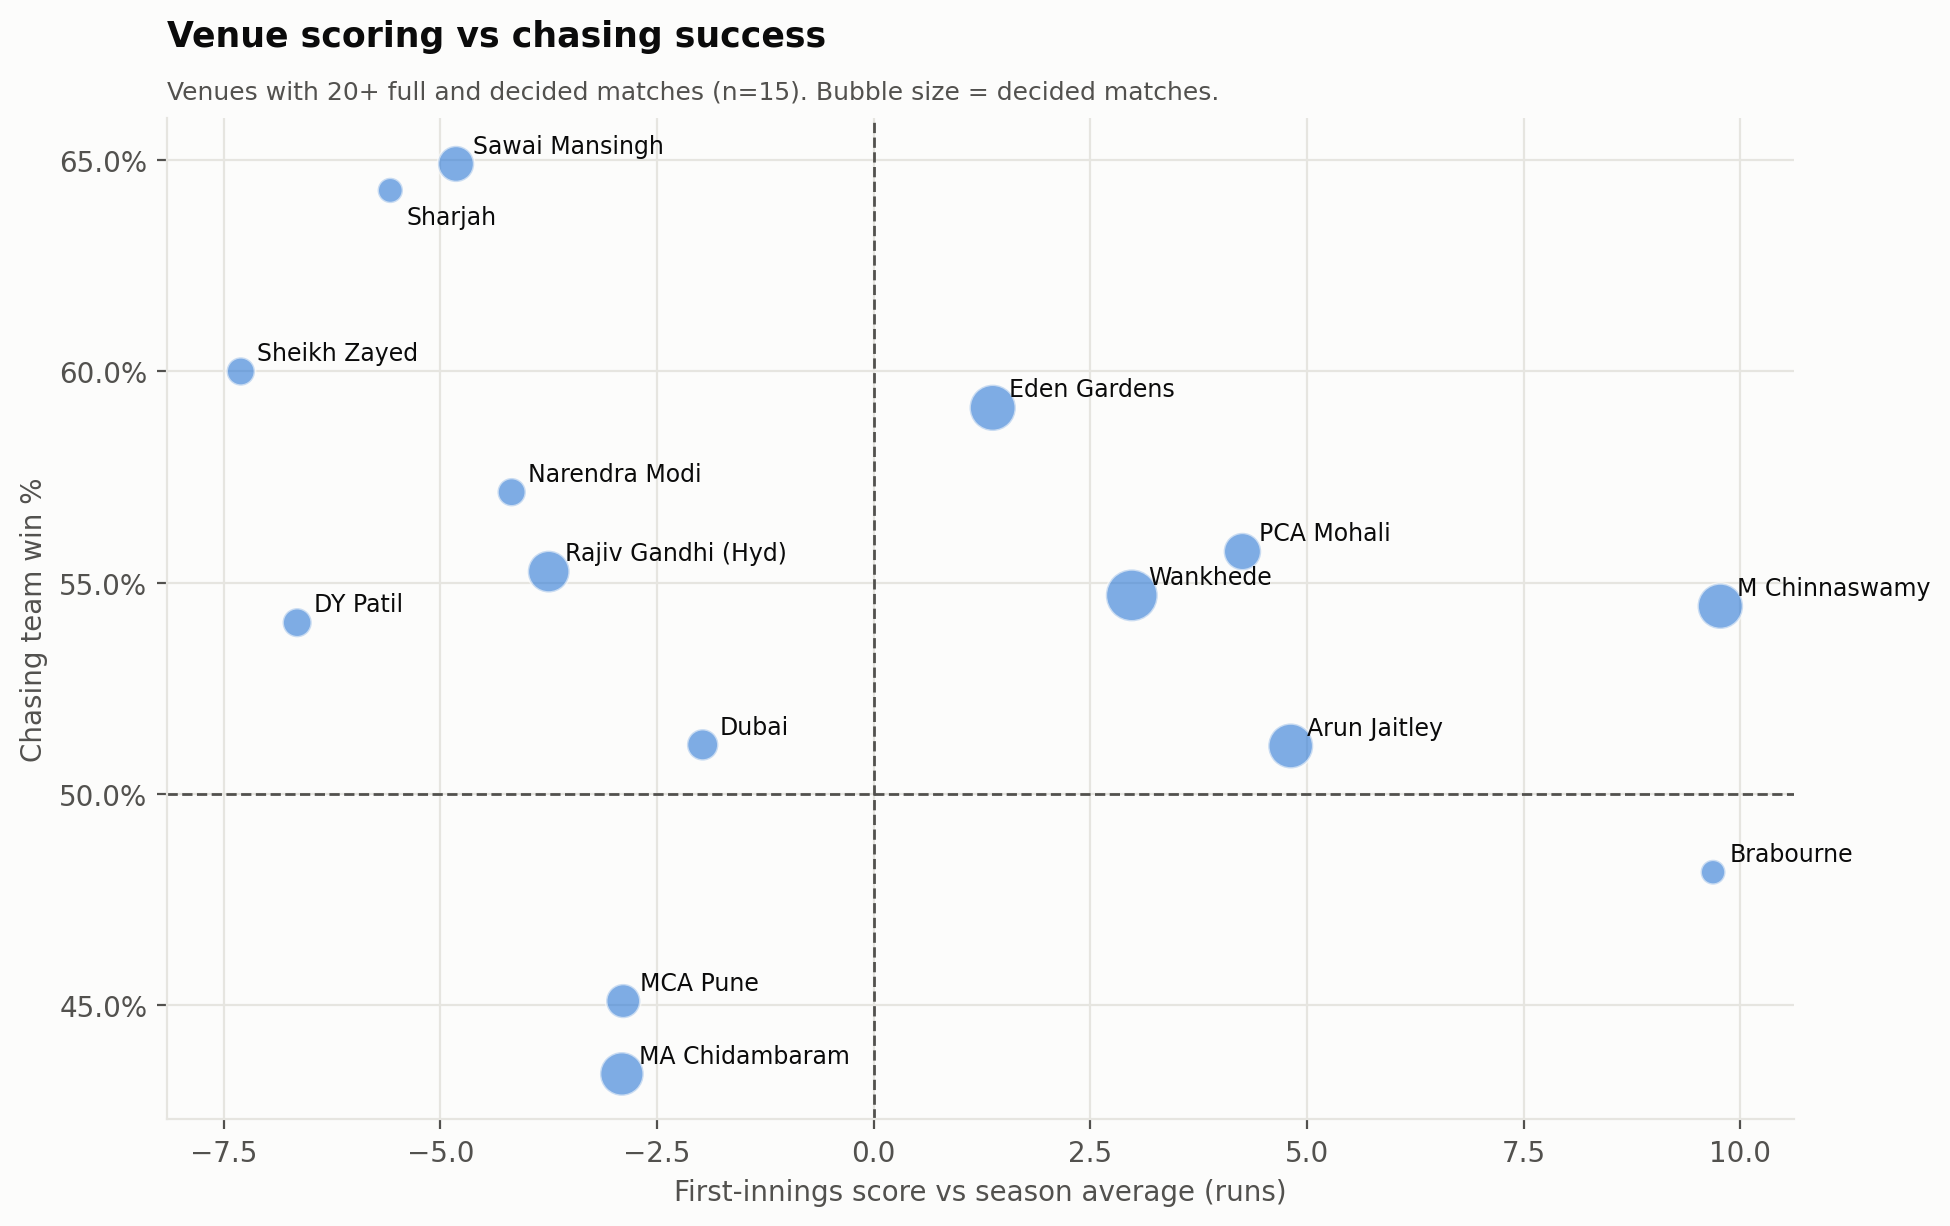

**Finding.** Among 15 venues with 20+ decided matches, chasing succeeds most at Sawai Mansingh Stadium (64.9% of 57) and Sharjah Cricket Stadium (64.3%), and least at MA Chidambaram Stadium (43.4% of 83). Sample sizes are small: 95% confidence intervals are 9-19 points wide either side. Only 1 venue(s) have an interval that excludes 50%: Sawai Mansingh Stadium; differences between the other venues may be chance.

**Limitation.** Small samples per venue; association only.

In [28]:
show('E4')

### E5 · Winning margins

**Question.** What are the most common winning margins?

**Why it matters.** Margins show competitive balance and how often matches go down to the wire.

**Metric.** result_margin for non-D/L matches, split by result_for; balls_remaining = target_balls - inn2_legal_balls.

,runs_margin,matches,pct
0,1-10,115,23.7
1,11-20,113,23.3
2,21-30,75,15.4
3,31-50,93,19.1
4,51+,90,18.5


**Wickets margins (chasing wins)**

,wickets_margin,matches,pct
0,1,4,0.7
1,2,10,1.8
2,3,31,5.4
3,4,58,10.2
4,5,96,16.9
5,6,119,20.9
6,7,113,19.9
7,8,76,13.4
8,9,47,8.3
9,10,15,2.6


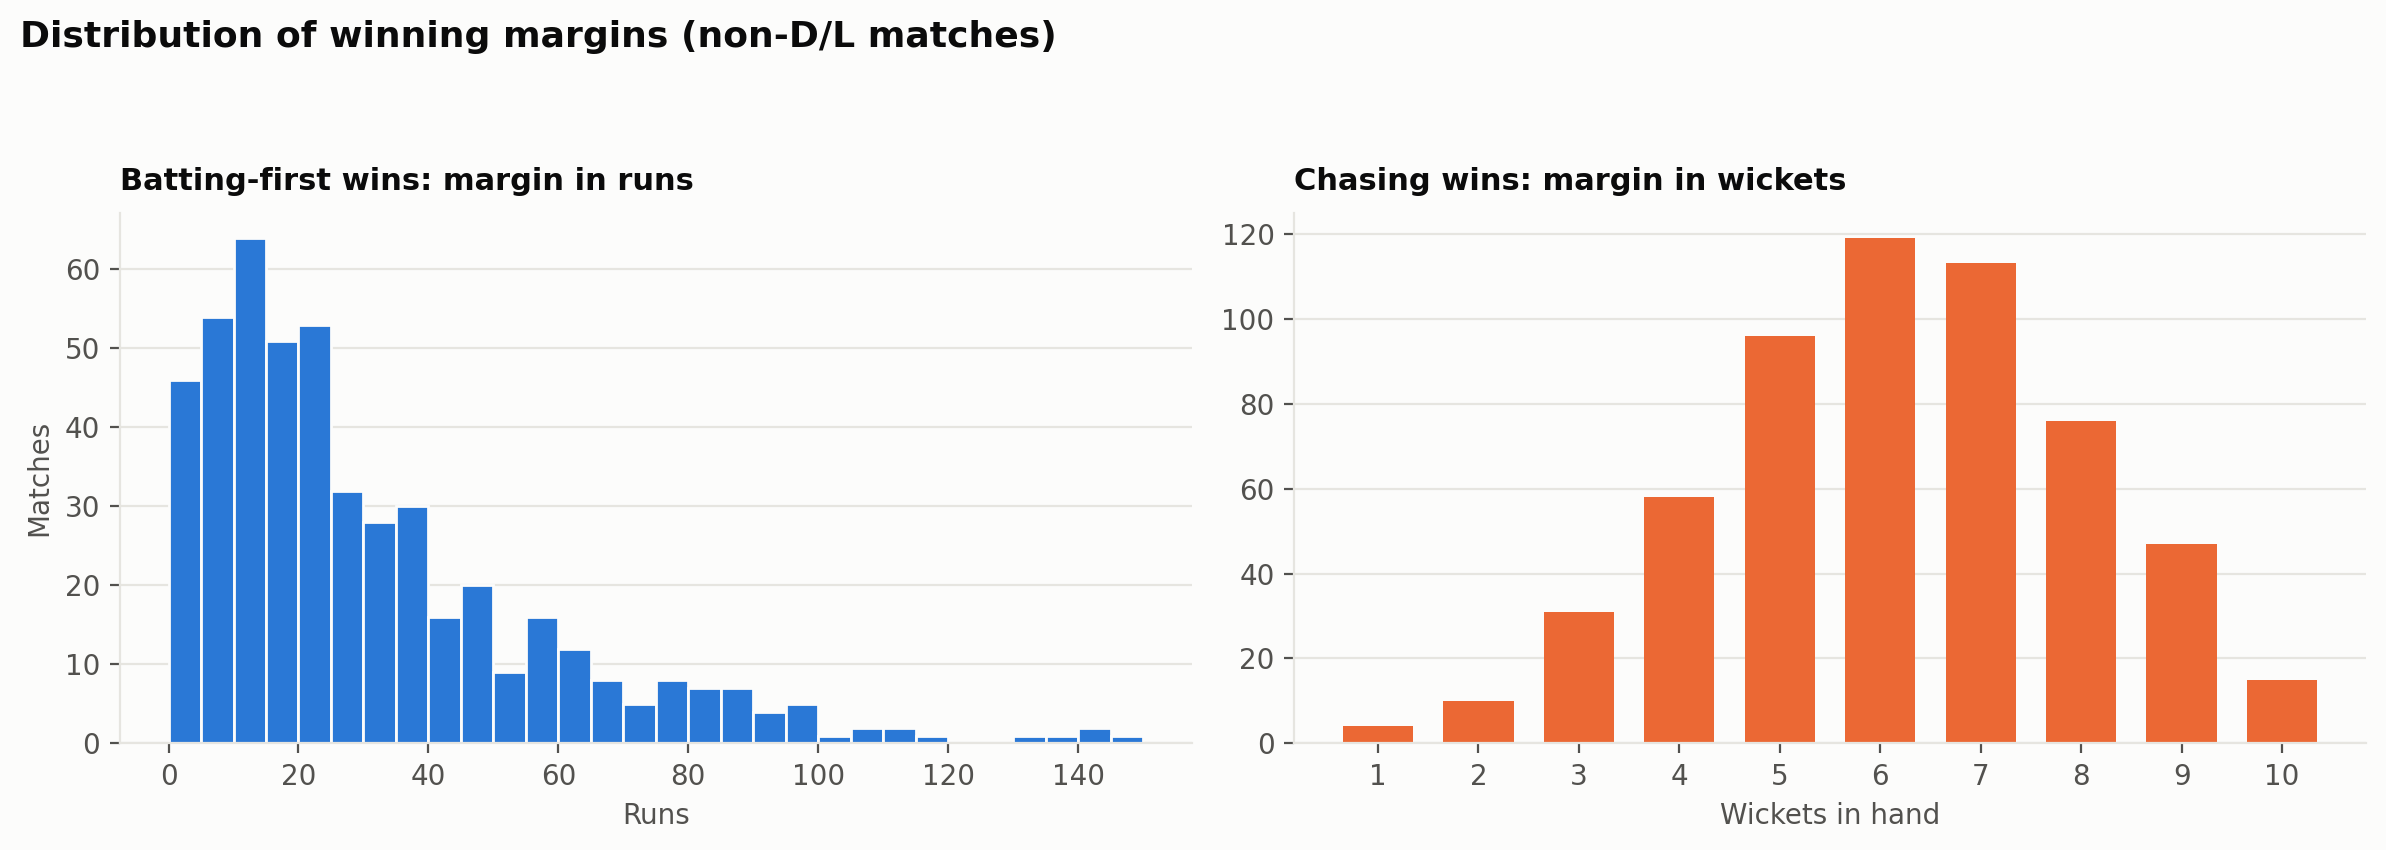

**Finding.** Batting-first wins have a median margin of 22 runs; 23.7% are by 10 runs or fewer and 18.5% by more than 50. Chasing wins are most often by 6 wickets (20.9%), with a median of 7 balls to spare. Using a 'close match' definition (won by <=10 runs, chase completed with <=6 balls left, or a tie), 391 of 1090 decided matches (35.9%) were close.

**Limitation.** D/L matches excluded because their margins are against a revised target.

In [29]:
show('E5')

### E6 · High- vs low-scoring venues

**Question.** Are there noticeable differences between high-scoring and low-scoring venues?

**Why it matters.** Tests whether venue scoring character translates into different match dynamics.

**Metric.** Qualifying venues split into terciles of avg_inn1_vs_season; compare run rate, sixes per full match, chase win %. Spearman rank correlation across venues.

,group,venues,avg_inn1_vs_season,run_rate,sixes_per_match,chase_win_pct,members
0,Low-scoring third,5,-5.71,8.14,11.61,60.08,Dr DY Patil Sports Academy; Narendra Modi Stadium; Sawai Mansingh Stadium; Sharjah Cricket Stadium; Sheikh Zayed Sta...
1,Middle third,5,-2.03,8.13,11.59,50.81,Dubai International Cricket Stadium; Eden Gardens; MA Chidambaram Stadium; Maharashtra Cricket Association Stadium; ...
2,High-scoring third,5,6.30,8.64,12.76,52.83,Arun Jaitley Stadium; Brabourne Stadium; M Chinnaswamy Stadium; Punjab Cricket Association IS Bindra Stadium; Wankhe...


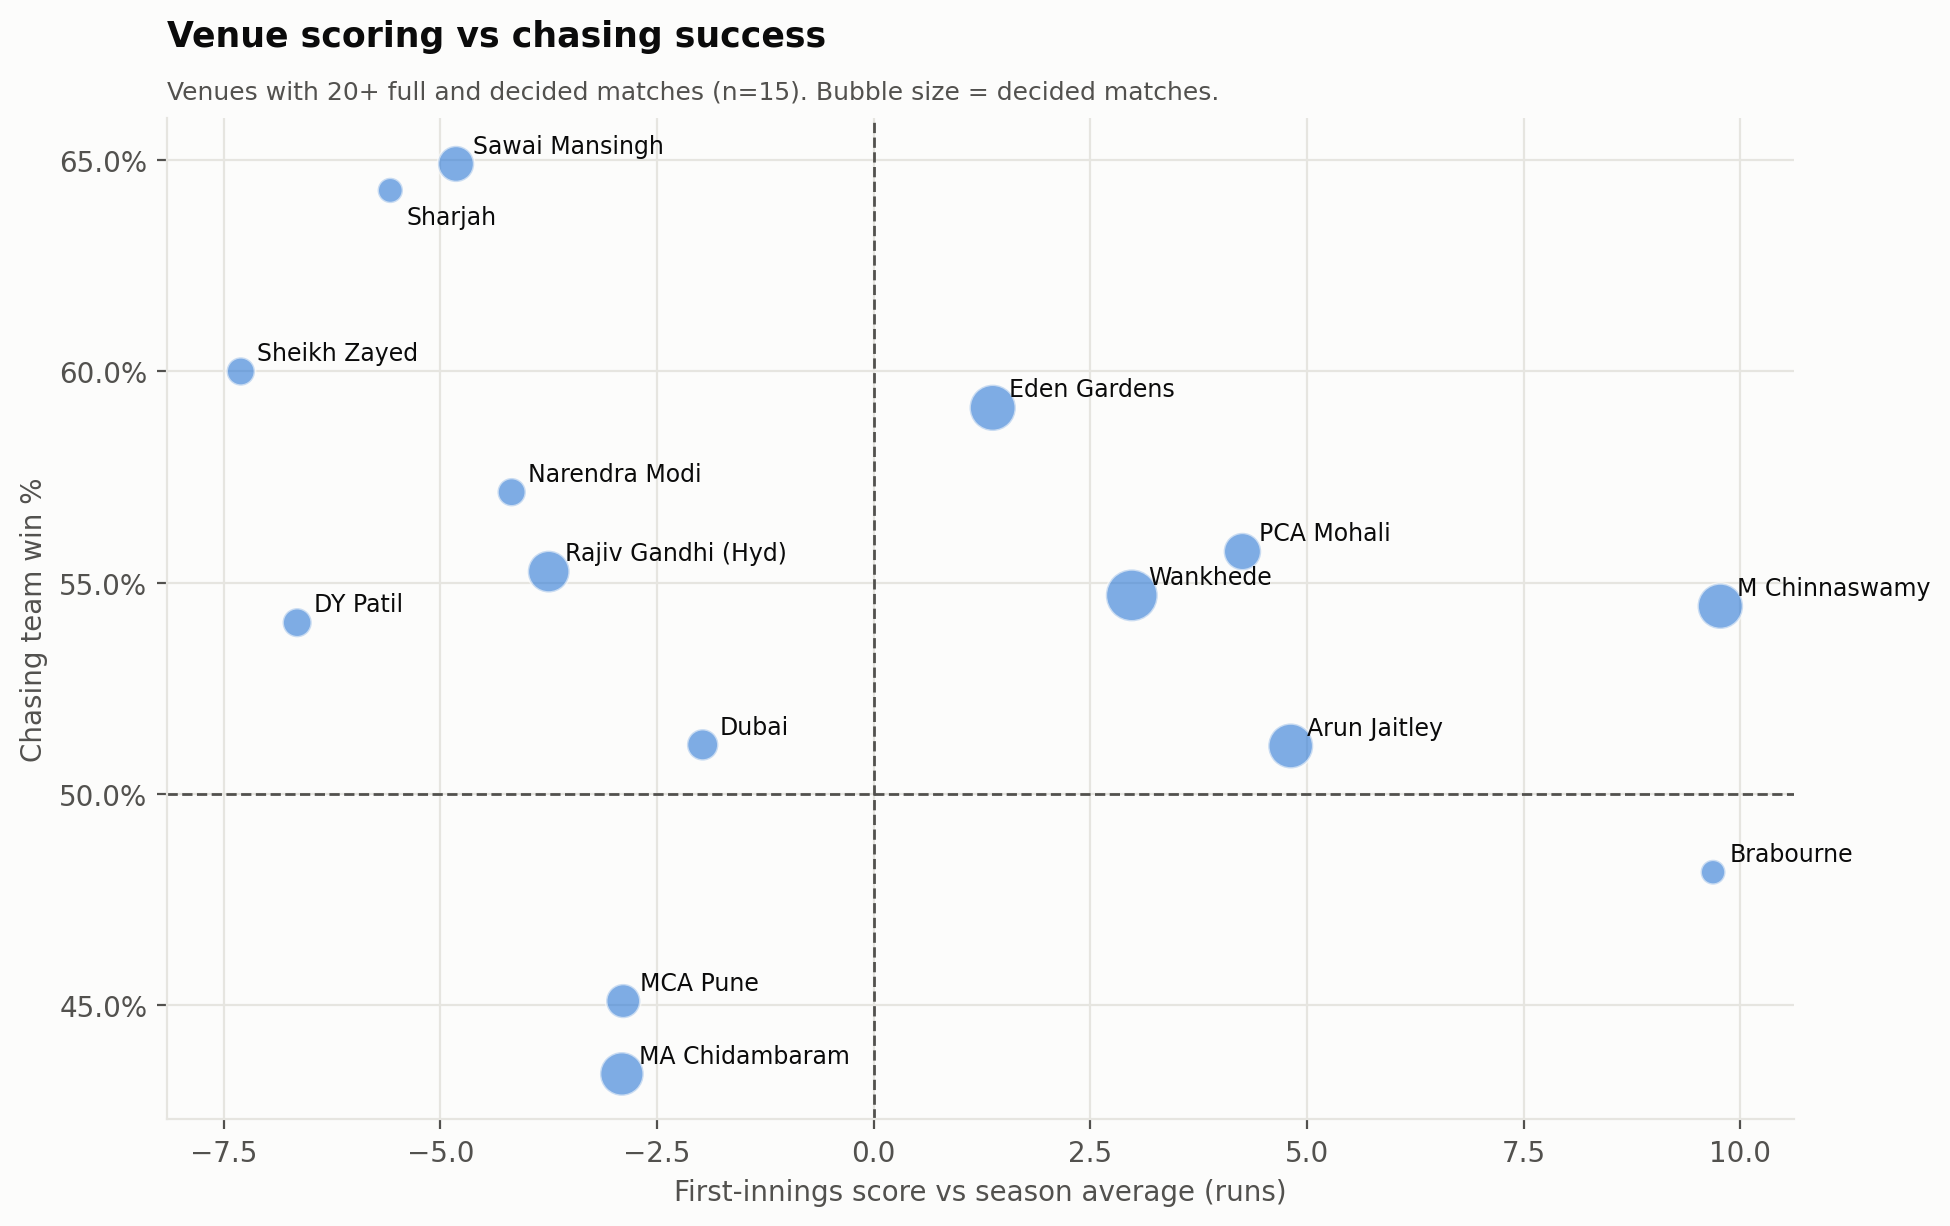

**Finding.** Splitting 15 qualifying venues into thirds by season-adjusted first-innings score: high-scoring venues average 8.64 runs/over and 12.8 sixes per match vs 8.14 and 11.6 at low-scoring venues. Chasing win % is 52.8% at high-scoring vs 60.1% at low-scoring venues. Across venues the rank correlation between scoring and chasing success is moderate and negative (Spearman rho = -0.46, p = 0.08, n = 15): higher-scoring grounds have tended to see slightly LESS chasing success, but with only 15 venues this is not statistically significant at the 5% level and should be treated as a hypothesis, not a rule.

**Limitation.** Small number of venues; correlation is descriptive.

In [30]:
show('E6')

## Super overs (analysed separately)
Super-over deliveries are excluded above; this is a short separate view.

In [31]:
so = D.so
summary = pd.DataFrame({'super_over_matches': [D.mc.is_super_over.sum()], 'deliveries': [len(so)],
                        'runs': [so.total_runs.sum()], 'bowler_wickets': [so.is_bowler_wicket.sum()]})
display(summary)
D.team_long[D.team_long.is_super_over == 1].groupby('team').agg(super_overs=('match_id', 'size'), won=('won', 'sum')) \
    .sort_values('super_overs', ascending=False)

,super_over_matches,deliveries,runs,bowler_wickets
0,14,161,286,20


,super_overs,won
team,,
Delhi Capitals,4,3
Kolkata Knight Riders,4,1
Mumbai Indians,4,2
Punjab Kings,4,3
Sunrisers Hyderabad,4,1
Rajasthan Royals,3,2
Royal Challengers Bengaluru,3,2
Chennai Super Kings,1,0
Gujarat Lions,1,0


## Outputs
- `reports/eda_report.md` - full written findings
- `reports/eda_validation_report.md`
- `reports/eda_summary.csv` - tidy summary of key tables
- `reports/eda_tables/` - every result table
- `reports/charts/` - charts (200 dpi PNG)